In [1]:
import pandas as pd
import numpy as np

In [2]:
FAO_FILE = r"..\data\processed\fao_syria_yield.csv"
NASA_FILE = r"..\data\processed\nasa_syria_climate.csv"

# fao

## check loaded data

In [3]:
fao_df = pd.read_csv(FAO_FILE)

In [4]:
fao_df.sample(10)

,country,crop,crop_code,element,year,unit,yield_hg_ha,flag
146,Syrian Arab Republic,"Lentils, dry",1704,Yield,2001,kg/ha,1275.9,A
397,Syrian Arab Republic,Sugar beet,1801,Yield,2014,kg/ha,40666.3,A
112,Syrian Arab Republic,Grapes,1330,Yield,2001,kg/ha,5652.6,A
481,Syrian Arab Republic,Wheat,111,Yield,1998,kg/ha,2388.5,A
506,Syrian Arab Republic,Wheat,111,Yield,2023,kg/ha,2306.2,A
456,Syrian Arab Republic,Tomatoes,1234,Yield,2007,kg/ha,64868.4,A
415,Syrian Arab Republic,Sunflower seed,1445,Yield,2000,kg/ha,2594.2,A
237,Syrian Arab Republic,Olives,1450,Yield,1996,kg/ha,1478.4,A
141,Syrian Arab Republic,"Lentils, dry",1704,Yield,1996,kg/ha,1076.3,A
282,Syrian Arab Republic,Potatoes,1510,Yield,2007,kg/ha,18342.7,A


In [5]:
fao_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 508 entries, 0 to 507
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   country      508 non-null    object 
 1   crop         508 non-null    object 
 2   crop_code    508 non-null    int64  
 3   element      508 non-null    object 
 4   year         508 non-null    int64  
 5   unit         508 non-null    object 
 6   yield_hg_ha  508 non-null    float64
 7   flag         508 non-null    object 
dtypes: float64(1), int64(2), object(5)
memory usage: 31.9+ KB


In [6]:
len(fao_df['crop'].unique()), fao_df['crop'].unique()

(16,
 array(['Apples', 'Barley', 'Chick peas, dry', 'Grapes', 'Lentils, dry',
        'Maize (corn)', 'Oats', 'Olives', 'Potatoes', 'Rice',
        'Sesame seed', 'Sorghum', 'Sugar beet', 'Sunflower seed',
        'Tomatoes', 'Wheat'], dtype=object))

In [7]:
len(fao_df['flag'].unique()), fao_df['flag'].unique()

(2, array(['A', 'E'], dtype=object))

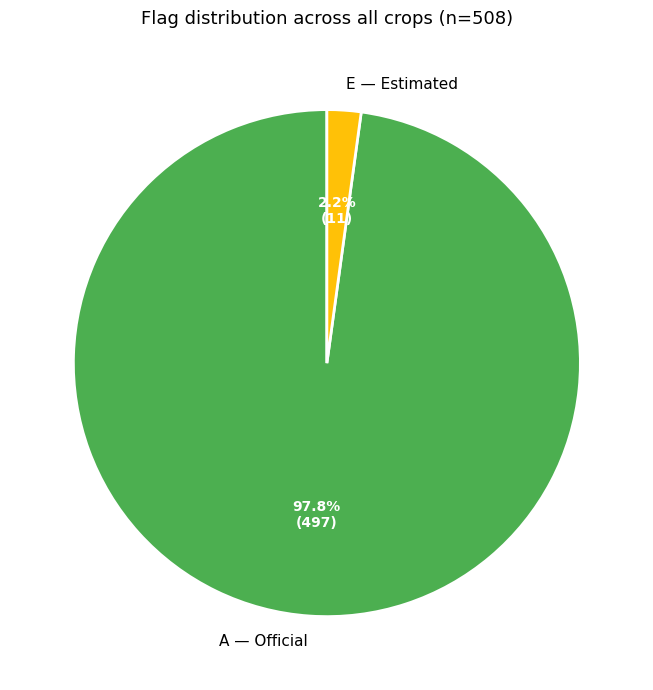

Flag counts:
flag
A    497
E     11

Percentages:
flag
A    97.83
E     2.17


In [8]:
import matplotlib.pyplot as plt

# Flag labels (add meanings in the legend so the plot is self-documenting)
FLAG_MEANING = {
    "A": "A — Official",
    "E": "E — Estimated",
    "I": "I — Imputed",
}

counts = fao_df["flag"].value_counts().sort_index()   # A, E, I order
labels = [FLAG_MEANING.get(f, f) for f in counts.index]
colors = {"A": "#4CAF50", "E": "#FFC107", "I": "#F44336"}
pie_colors = [colors.get(f, "gray") for f in counts.index]

fig, ax = plt.subplots(figsize=(7, 7))
wedges, texts, autotexts = ax.pie(
    counts.values,
    labels=labels,
    autopct=lambda p: f"{p:.1f}%\n({int(round(p * counts.sum() / 100))})",
    startangle=90,
    colors=pie_colors,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 11},
)

for t in autotexts:
    t.set_fontsize(10)
    t.set_fontweight("bold")
    t.set_color("white")

ax.set_title(f"Flag distribution across all crops (n={counts.sum()})",
             fontsize=13, pad=16)
plt.tight_layout()
plt.show()

print("Flag counts:")
print(counts.to_string())
print(f"\nPercentages:")
print((counts / counts.sum() * 100).round(2).to_string())

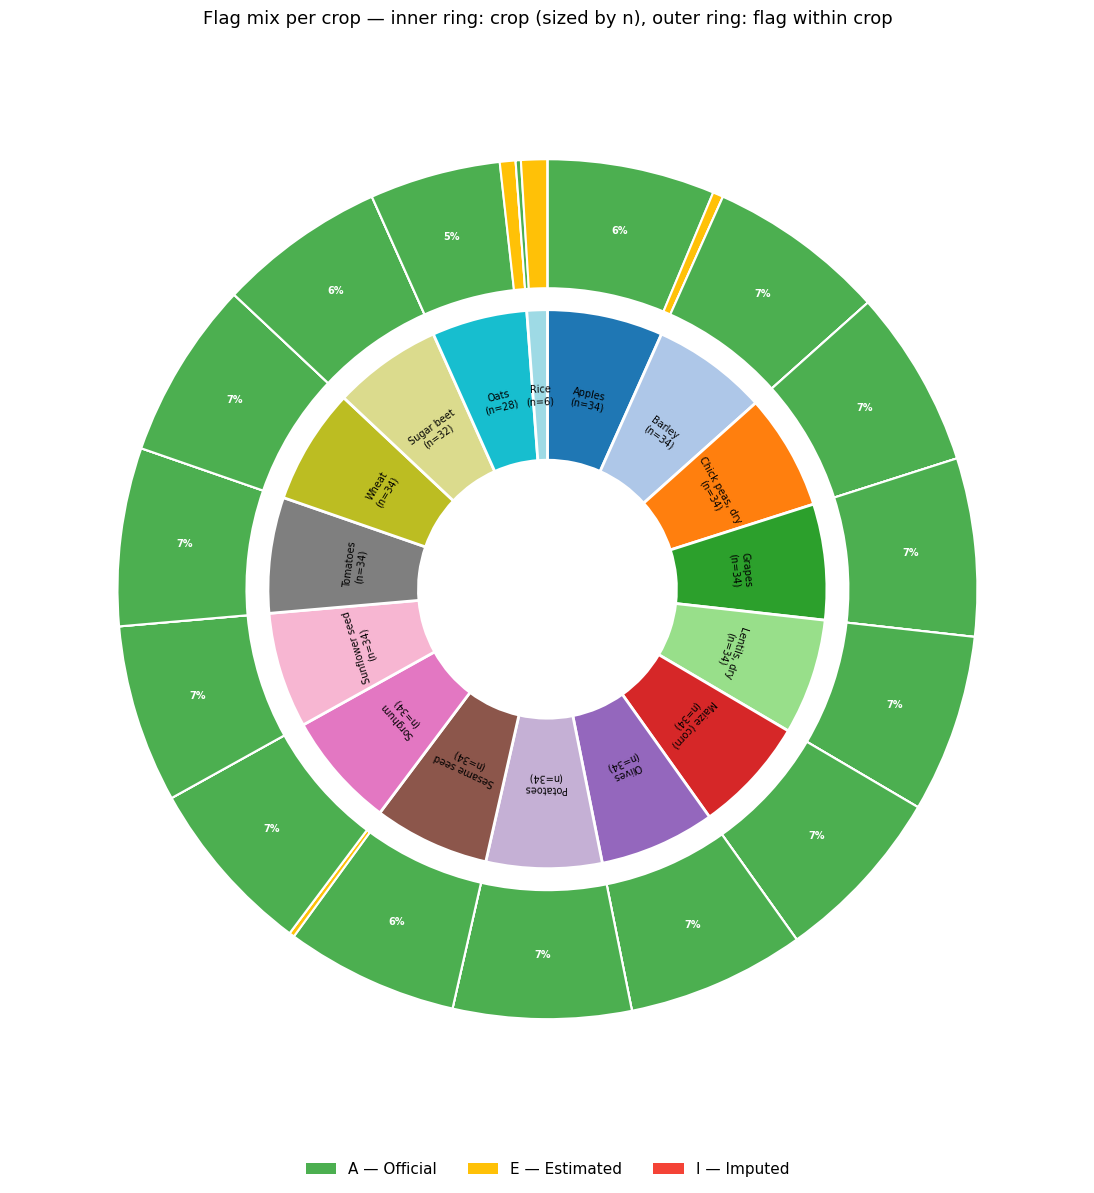

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# ── Prepare the data ────────────────────────────────────────
# Count of (crop, flag) pairs, ordered A → E → I inside each crop
flag_order  = ["A", "E", "I"]
flag_colors = {"A": "#4CAF50", "E": "#FFC107", "I": "#F44336"}

pivot = (
    fao_df.pivot_table(index="crop", columns="flag",
                    values="yield_hg_ha", aggfunc="count", fill_value=0)
      .reindex(columns=flag_order, fill_value=0)
)
pivot["total"] = pivot.sum(axis=1)
pivot = pivot.sort_values("total", ascending=False)   # largest crops first

# Inner ring sizes = total rows per crop
inner_sizes  = pivot["total"].values
inner_labels = pivot.index.tolist()

# Outer ring sizes = (crop, flag) row counts, preserving crop order
outer_sizes  = pivot[flag_order].values.flatten()
outer_colors = [flag_colors[f] for f in flag_order] * len(pivot)

# ── Draw ────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 12))

# Inner ring: crops
inner_wedges, _ = ax.pie(
    inner_sizes,
    radius=0.65,
    colors=plt.cm.tab20(np.linspace(0, 1, len(inner_sizes))),
    wedgeprops={"edgecolor": "white", "linewidth": 2, "width": 0.35},
    startangle=90,
    counterclock=False,
)

# Outer ring: flags, aligned angularly with inner ring
outer_wedges, _ = ax.pie(
    outer_sizes,
    radius=1.0,
    colors=outer_colors,
    wedgeprops={"edgecolor": "white", "linewidth": 1.5, "width": 0.30},
    startangle=90,
    counterclock=False,
)

# ── Labels on the inner ring (crop names, radial placement) ─
for wedge, label, count in zip(inner_wedges, inner_labels, inner_sizes):
    angle = (wedge.theta2 + wedge.theta1) / 2
    x = 0.45 * np.cos(np.deg2rad(angle))
    y = 0.45 * np.sin(np.deg2rad(angle))
    # Rotate label to be readable
    rotation = angle - 90 if angle < 90 or angle > 270 else angle + 90
    ax.text(x, y, f"{label}\n(n={count})",
            ha="center", va="center",
            fontsize=7, rotation=rotation,
            rotation_mode="anchor")

# ── Percentage labels on the outer ring ────────────────────
for wedge, size in zip(outer_wedges, outer_sizes):
    if size == 0:
        continue
    angle = (wedge.theta2 + wedge.theta1) / 2
    pct = 100 * size / outer_sizes.sum()
    if pct < 1.5:      # skip tiny slices to avoid clutter
        continue
    x = 0.85 * np.cos(np.deg2rad(angle))
    y = 0.85 * np.sin(np.deg2rad(angle))
    ax.text(x, y, f"{pct:.0f}%",
            ha="center", va="center",
            fontsize=7, color="white", fontweight="bold")

# ── Legend ─────────────────────────────────────────────────
from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor=flag_colors["A"], label="A — Official"),
    Patch(facecolor=flag_colors["E"], label="E — Estimated"),
    Patch(facecolor=flag_colors["I"], label="I — Imputed"),
]
ax.legend(handles=legend_handles,
          loc="upper center", bbox_to_anchor=(0.5, -0.02),
          ncol=3, fontsize=11, frameon=False)

ax.set_title(
    "Flag mix per crop — inner ring: crop (sized by n), outer ring: flag within crop",
    fontsize=13, pad=20,
)
ax.set(aspect="equal")
plt.tight_layout()
plt.show()

A — Official Value
This is the most trustworthy flag. It means the data point was reported directly by a national source (like a government ministry or official questionnaire) and is considered an observed statistic . For your modeling, these rows represent the "ground truth" of Syrian crop yields.

E — Estimated Value
This means FAO calculated the number because a direct official figure wasn't available. It could be derived from related data (like calculating yield from production and area) or based on assumptions . While still based on real data, it introduces a layer of calculation. In your EDA, a crop with a high percentage of E flags might show a smoother or less erratic trend than reality.

I — Imputed Value
This is the most important flag to watch. It means the value is fabricated by FAO to fill a gap in the time series . Common methods include carrying the last known value forward or drawing a straight line between two existing data points . For machine learning, this is dangerous: the model might learn the imputation pattern (e.g., "yield is always the same as last year") rather than the actual relationship between climate and crops.

In [10]:
"Year range:", fao_df['year'].min(), "to", fao_df['year'].max()

('Year range:', np.int64(1991), 'to', np.int64(2024))

In [11]:
fao_df['year'] = pd.to_datetime(fao_df["year"].astype(int).astype(str), format="%Y")
"Year range:", fao_df['year'].min(), "to", fao_df['year'].max()

('Year range:',
 Timestamp('1991-01-01 00:00:00'),
 'to',
 Timestamp('2024-01-01 00:00:00'))

In [12]:
fao_df.describe()

,crop_code,year,yield_hg_ha
count,508.000000,508,508.000000
mean,1032.338583,2007-03-20 11:28:49.133858048,9275.218504
min,111.000000,1991-01-01 00:00:00,150.100000
25%,115.000000,1999-01-01 00:00:00,882.075000
50%,1341.000000,2007-01-01 00:00:00,1789.550000
75%,1510.000000,2016-01-01 00:00:00,6511.650000
max,1801.000000,2024-01-01 00:00:00,76775.600000
std,667.487541,NaN,15945.179149


- convert 'year' column to datetime type
- train on A — Official Value flag only
- drop crops with null values

## Per-crop histogram

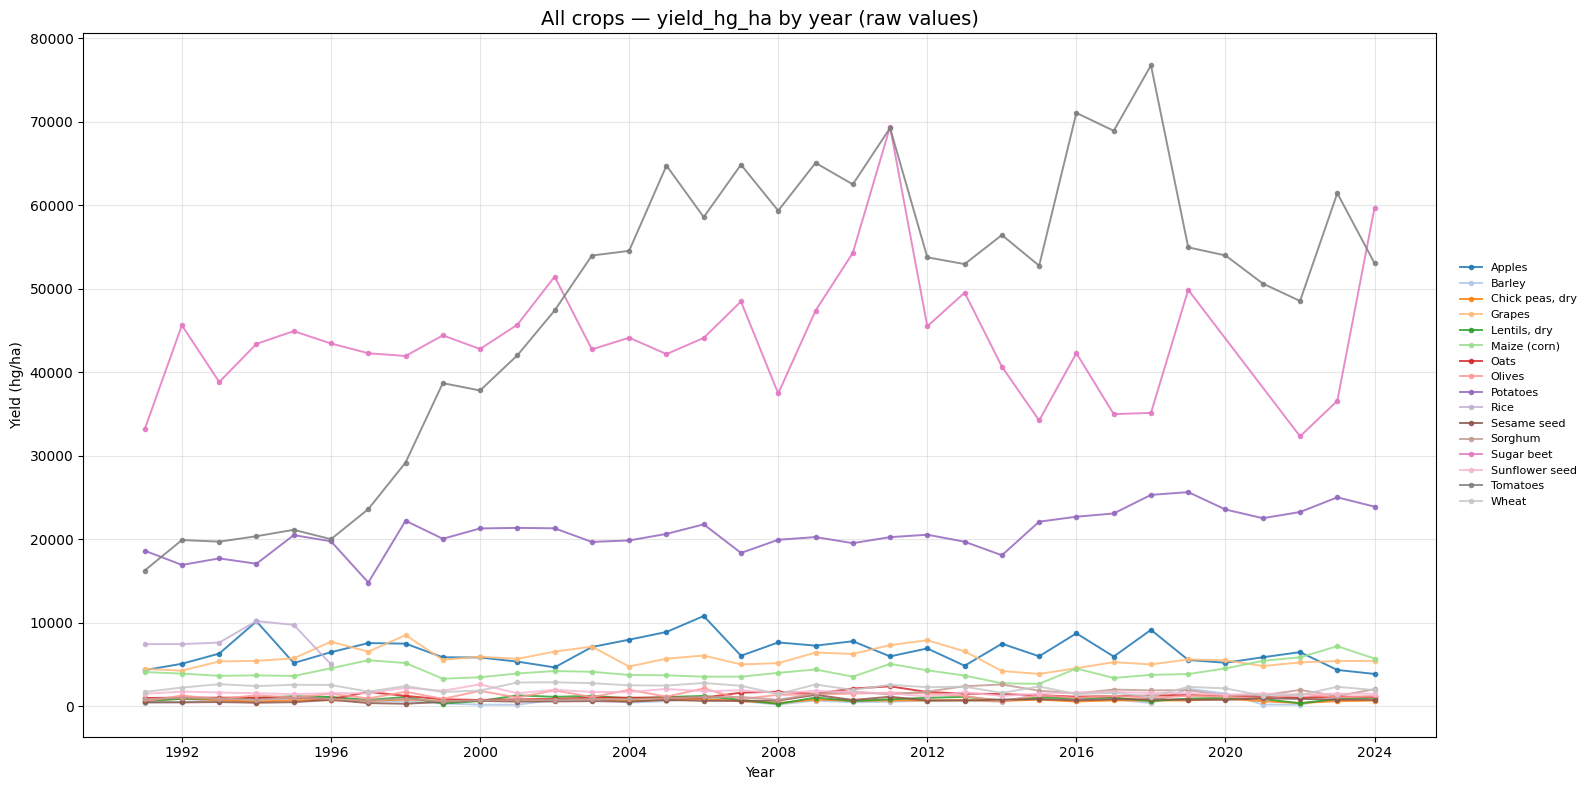

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

TARGET = "yield_hg_ha"
crops_list = sorted(fao_df["crop"].unique())

fig, ax = plt.subplots(figsize=(16, 8))

# Use a distinct color per crop
cmap = plt.get_cmap("tab20")
for i, crop in enumerate(crops_list):
    sub = fao_df[fao_df["crop"] == crop].sort_values("year")
    ax.plot(sub["year"], sub[TARGET],
            marker="o", markersize=3, linewidth=1.4,
            color=cmap(i % 20), label=crop, alpha=0.85)

ax.set_title(f"All crops — {TARGET} by year (raw values)", fontsize=14)
ax.set_xlabel("Year")
ax.set_ylabel("Yield (hg/ha)")
ax.grid(True, alpha=0.3)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5),
          fontsize=8, ncol=1, frameon=False)
plt.tight_layout()
plt.show()

In [14]:
import pandas as pd
import numpy as np

TARGET = "yield_hg_ha"

# ── Build the per-crop statistics table ─────────────────────
stats = (
    fao_df.groupby("crop")[TARGET]
      .agg(
          n         = "count",
          min       = "min",
          p05       = lambda s: s.quantile(0.05),
          p25       = lambda s: s.quantile(0.25),
          median    = "median",
          mean      = "mean",
          p75       = lambda s: s.quantile(0.75),
          p95       = lambda s: s.quantile(0.95),
          max       = "max",
          std       = "std",
      )
      .assign(
          cv        = lambda d: d["std"] / d["mean"],                    # coefficient of variation
          range_x   = lambda d: d["max"] / d["min"].replace(0, np.nan),  # dynamic range (max/min)
          iqr       = lambda d: d["p75"] - d["p25"],                     # interquartile range
      )
      .sort_values("mean", ascending=False)
)

# ── Also pull year coverage per crop ────────────────────────
years_per_crop = (
    fao_df.groupby("crop")["year"]
      .agg(year_min="min", year_max="max", n_years="nunique")
)
stats = stats.join(years_per_crop)

# ── Pretty-print ────────────────────────────────────────────
pd.set_option("display.float_format", "{:,.1f}".format)
pd.set_option("display.width", 200)

print("=" * 120)
print("PER-CROP STATISTICS")
print("=" * 120)
print(stats.to_string())

PER-CROP STATISTICS
                  n      min      p05      p25   median     mean      p75      p95      max      std  cv  range_x      iqr   year_min   year_max  n_years
crop                                                                                                                                                     
Tomatoes         34 16,230.8 19,819.4 38,029.1 53,409.9 48,359.4 60,924.3 69,896.7 76,775.6 17,522.8 0.4      4.7 22,895.2 1991-01-01 2024-01-01       34
Sugar beet       32 32,314.8 33,736.1 40,205.3 43,418.2 44,025.4 46,117.1 56,728.3 69,392.8  7,666.0 0.2      2.1  5,911.9 1991-01-01 2024-01-01       32
Potatoes         34 14,797.3 16,999.1 19,666.8 20,501.5 20,788.0 22,426.8 25,106.7 25,630.5  2,479.9 0.1      1.7  2,760.1 1991-01-01 2024-01-01       34
Rice              6  5,000.0  5,602.9  7,414.1  7,510.6  7,888.6  9,191.7 10,062.9 10,176.5  1,869.2 0.2      2.0  1,777.5 1991-01-01 1996-01-01        6
Apples           34  3,842.9  4,311.6  5,369.1  6,152.4 

- values ranges a lot, some crops reachs +50K, while some 700 only
- there are missing data for some crops (maybe was not planted)

- keep only regular crops (which must will reflect the change in climate not in agricultural policies) - Potatoes, Wheat, Maize (corn), Olives, Sunflower seed
- keep the period that represents similar conditions (mechnical, tools and other conditions) similar to know (last 20 years only)

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

TARGET = "yield_hg_ha"

# ── 1. Filter to regular (climate-driven) crops ───────────────
CROPS = ["Potatoes", "Wheat", "Maize", "Olives", "Sunflower seed"]

available = set(fao_df["crop"].unique())
missing   = [c for c in CROPS if c not in available]
if missing:
    print(f"[WARN] Crops not found in dataset: {missing}")
    print(f"       Available crops: {sorted(available)}")

fao_filtered = fao_df[fao_df["crop"].isin(CROPS)].copy()

# ── 2. Coerce year to int (handles datetime / string / float) ─
if pd.api.types.is_datetime64_any_dtype(fao_filtered["year"]):
    fao_filtered["year"] = fao_filtered["year"].dt.year
else:
    fao_filtered["year"] = pd.to_numeric(fao_filtered["year"], errors="coerce")
fao_filtered["year"] = fao_filtered["year"].astype("Int64")

# ── 3. Keep the last 20 years ─────────────────────────────────
YEAR_END   = int(fao_filtered["year"].max())
YEAR_START = YEAR_END - 20

fao_filtered = fao_filtered[
    (fao_filtered["year"] >= YEAR_START) &
    (fao_filtered["year"] <= YEAR_END)
].copy()

# ── 4. Print filter details ──────────────────────────────────
print("=" * 90)
print(f"FILTER APPLIED — crops={CROPS}, years={YEAR_START}–{YEAR_END}")
print("=" * 90)
print(f"  year dtype      : {fao_filtered['year'].dtype}")
print(f"  total rows      : {len(fao_filtered):,}")
print(f"  crops present   : {sorted(fao_filtered['crop'].unique())}")
print(f"\n  per-crop counts :")
print(fao_filtered.groupby("crop").size().to_string())

# ── 5. Per-crop statistics ───────────────────────────────────
stats = (
    fao_filtered.groupby("crop")[TARGET]
      .agg(
          n         = "count",
          min       = "min",
          p05       = lambda s: s.quantile(0.05),
          p25       = lambda s: s.quantile(0.25),
          median    = "median",
          mean      = "mean",
          p75       = lambda s: s.quantile(0.75),
          p95       = lambda s: s.quantile(0.95),
          max       = "max",
          std       = "std",
      )
      .assign(
          cv        = lambda d: d["std"] / d["mean"],
          range_x   = lambda d: d["max"] / d["min"].replace(0, np.nan),
          iqr       = lambda d: d["p75"] - d["p25"],
      )
      .sort_values("mean", ascending=False)
)

years_per_crop = (
    fao_filtered.groupby("crop")["year"]
      .agg(year_min="min", year_max="max", n_years="nunique")
)
stats = stats.join(years_per_crop)

pd.set_option("display.float_format", "{:,.1f}".format)
pd.set_option("display.width", 200)

print("\n" + "=" * 120)
print(f"PER-CROP STATISTICS — crops={CROPS}, years={YEAR_START}–{YEAR_END}")
print("=" * 120)
print(stats.to_string())


[WARN] Crops not found in dataset: ['Maize']
       Available crops: ['Apples', 'Barley', 'Chick peas, dry', 'Grapes', 'Lentils, dry', 'Maize (corn)', 'Oats', 'Olives', 'Potatoes', 'Rice', 'Sesame seed', 'Sorghum', 'Sugar beet', 'Sunflower seed', 'Tomatoes', 'Wheat']
FILTER APPLIED — crops=['Potatoes', 'Wheat', 'Maize', 'Olives', 'Sunflower seed'], years=2004–2024
  year dtype      : Int64
  total rows      : 84
  crops present   : ['Olives', 'Potatoes', 'Sunflower seed', 'Wheat']

  per-crop counts :
crop
Olives            21
Potatoes          21
Sunflower seed    21
Wheat             21

PER-CROP STATISTICS — crops=['Potatoes', 'Wheat', 'Maize', 'Olives', 'Sunflower seed'], years=2004–2024
                 n      min      p05      p25   median     mean      p75      p95      max     std  cv  range_x     iqr  year_min  year_max  n_years
crop                                                                                                                                                
P

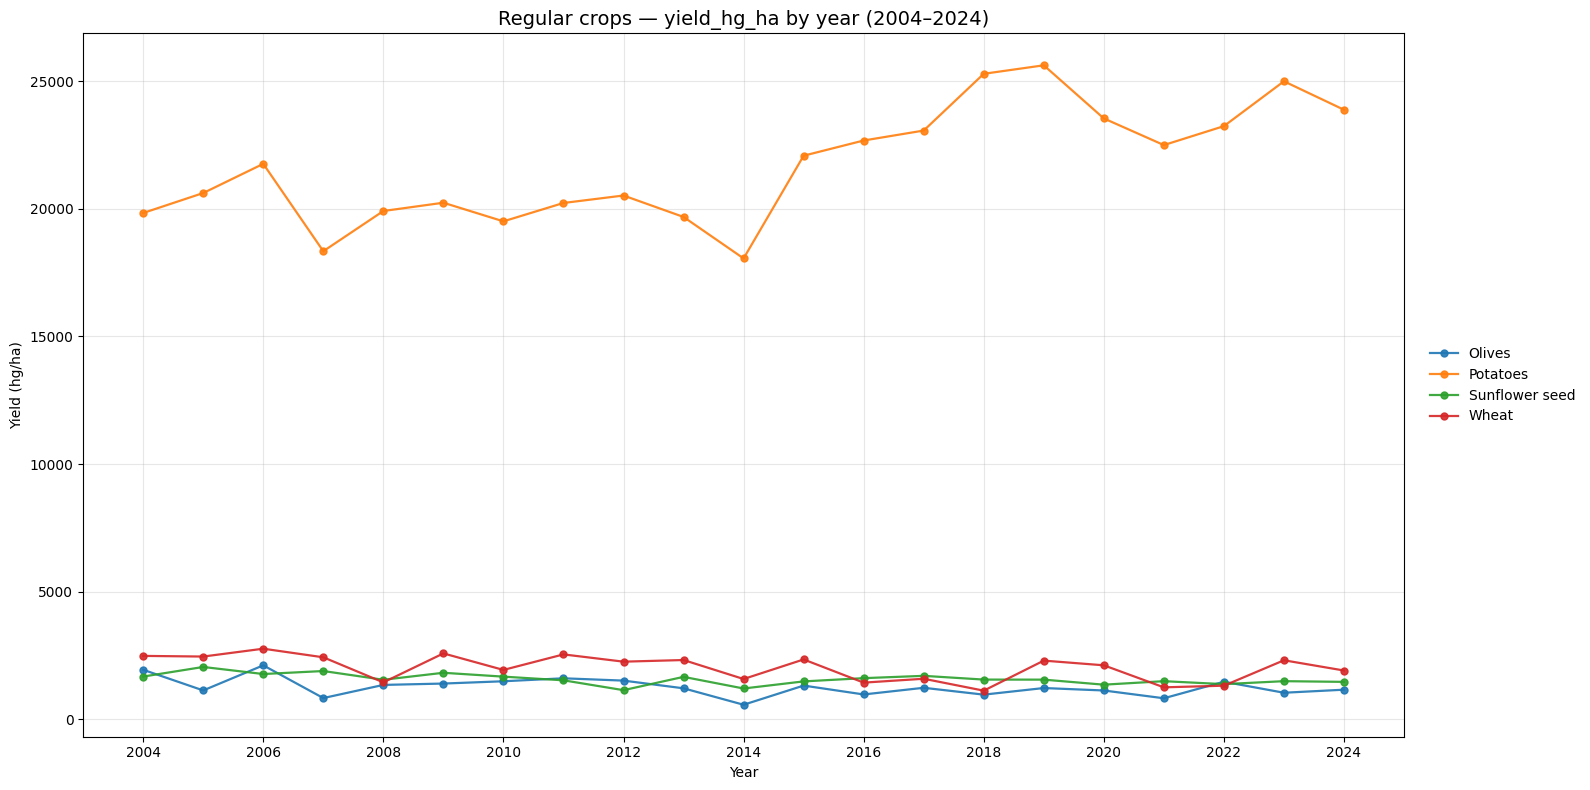

In [16]:
crops_list = sorted(fao_filtered["crop"].unique())

fig, ax = plt.subplots(figsize=(16, 8))

cmap = plt.get_cmap("tab10")
for i, crop in enumerate(crops_list):
    sub = fao_filtered[fao_filtered["crop"] == crop].sort_values("year")
    ax.plot(sub["year"], sub[TARGET],
            marker="o", markersize=5, linewidth=1.6,
            color=cmap(i % 10), label=crop, alpha=0.9)

ax.set_title(
    f"Regular crops — {TARGET} by year ({YEAR_START}–{YEAR_END})",
    fontsize=14,
)
ax.set_xlabel("Year")
ax.set_ylabel("Yield (hg/ha)")
ax.grid(True, alpha=0.3)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5),
          fontsize=10, ncol=1, frameon=False)

# Force integer year ticks (avoid 2005.0, 2006.5, …)
ax.set_xticks(range(YEAR_START, YEAR_END + 1, 2))

plt.tight_layout()
plt.show()

In [17]:
# ══════════════════════════════════════════════════════════════════
# NASA climate data — load, aggregate daily → yearly per governorate
# ══════════════════════════════════════════════════════════════════
import warnings
from scipy.stats import multivariate_normal

nasa_df = pd.read_csv(NASA_FILE, parse_dates=['date'])
nasa_df['year'] = nasa_df['date'].dt.year
nasa_df = nasa_df.dropna()

CLIMATE_FEATURES = [
    't2m', 't2m_max', 't2m_min',
    'prectotcorr', 'rh2m', 'solar_kwh_m2', 'ws2m',
]

# Aggregate daily → yearly per (governorate, year)
nasa_yearly_df = (
    nasa_df.groupby(['governorate', 'year'])
           .agg(
               t2m            = ('t2m',           'mean'),
               t2m_max        = ('t2m_max',       'max'),
               t2m_min        = ('t2m_min',       'min'),
               prectotcorr    = ('prectotcorr',   'sum'),
               rh2m           = ('rh2m',          'mean'),
               solar_kwh_m2   = ('solar_kwh_m2',  'mean'),
               ws2m           = ('ws2m',          'mean'),
               n_days         = ('date',          'count'),
           )
           .reset_index()
)
# Keep only years with near-complete data (≥ 300 days)
nasa_yearly_df = nasa_yearly_df[nasa_yearly_df['n_days'] >= 300].reset_index(drop=True)

govs = sorted(nasa_yearly_df['governorate'].unique())
print(f"NASA yearly data: {nasa_yearly_df.shape}, governorates={len(govs)}")
print(f"Year range: {nasa_yearly_df['year'].min()} → {nasa_yearly_df['year'].max()}")


# Same detector as in 00_anomaly_detection — reused here
def detect_anomalies_for_gov(df, gov, feature, z_thresh=2.0):
    sub = (df[df['governorate'] == gov]
           .sort_values('year').reset_index(drop=True))
    finite = np.isfinite(sub[feature].values.astype(float))
    sub = sub.loc[finite].reset_index(drop=True)
    if len(sub) < 3:
        return sub, None, None, np.zeros(len(sub), dtype=bool)

    X = sub[['year', feature]].values.astype(float)
    mu = X.mean(axis=0)
    sigma = np.cov(X, rowvar=False) + np.eye(2) * 1e-6
    p = multivariate_normal(mean=mu, cov=sigma).pdf(X)
    log_p = np.log(p + 1e-300)
    resid = X[:, 1] - np.polyval(np.polyfit(X[:, 0], X[:, 1], 1), X[:, 0])
    resid_z = np.abs((resid - resid.mean()) / (resid.std() + 1e-12))
    outlier_mask = resid_z > z_thresh
    return sub, X, log_p, outlier_mask


FEATURE_LABELS = {
    't2m'          : 'T2M mean (°C)',
    't2m_max'      : 'T2M max (°C)',
    't2m_min'      : 'T2M min (°C)',
    'prectotcorr'  : 'Precip (mm/yr)',
    'rh2m'         : 'RH2M (%)',
    'solar_kwh_m2' : 'Solar (kWh/m²)',
    'ws2m'         : 'Wind (m/s)',
}

# Restrict the climate view to the same years as the filtered FAO data
CLIMATE_YEAR_START = YEAR_START
CLIMATE_YEAR_END   = YEAR_END
nasa_yearly_filtered = nasa_yearly_df[
    (nasa_yearly_df['year'] >= CLIMATE_YEAR_START) &
    (nasa_yearly_df['year'] <= CLIMATE_YEAR_END)
].copy()

print(f"\nClimate filtered to {CLIMATE_YEAR_START}–{CLIMATE_YEAR_END}: "
      f"{nasa_yearly_filtered.shape}")

NASA yearly data: (456, 10), governorates=13
Year range: 1991 → 2026

Climate filtered to 2004–2024: (273, 10)


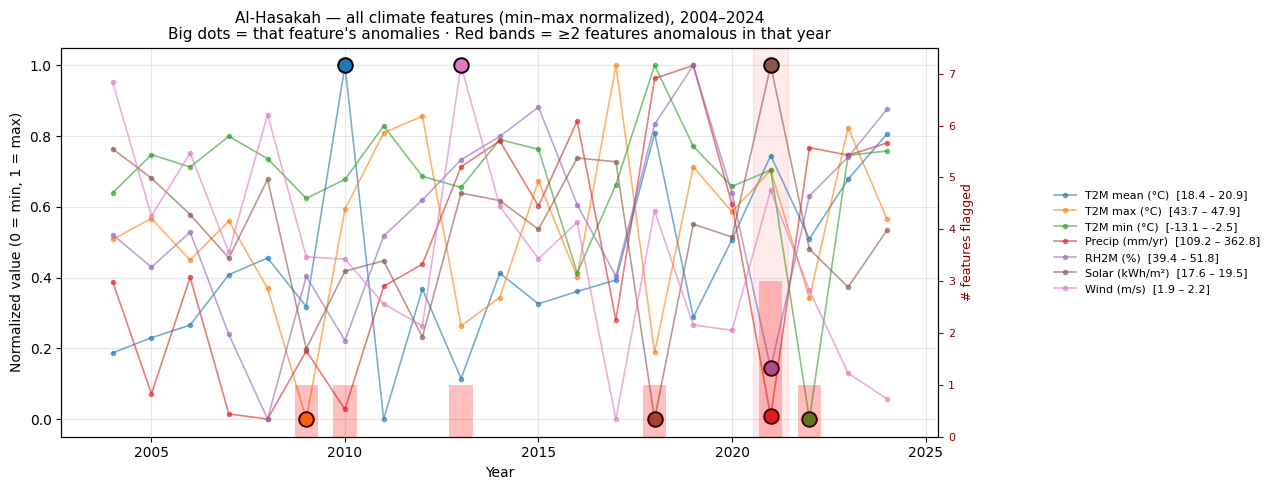

Al-Hasakah     strong anomaly years: [2021]


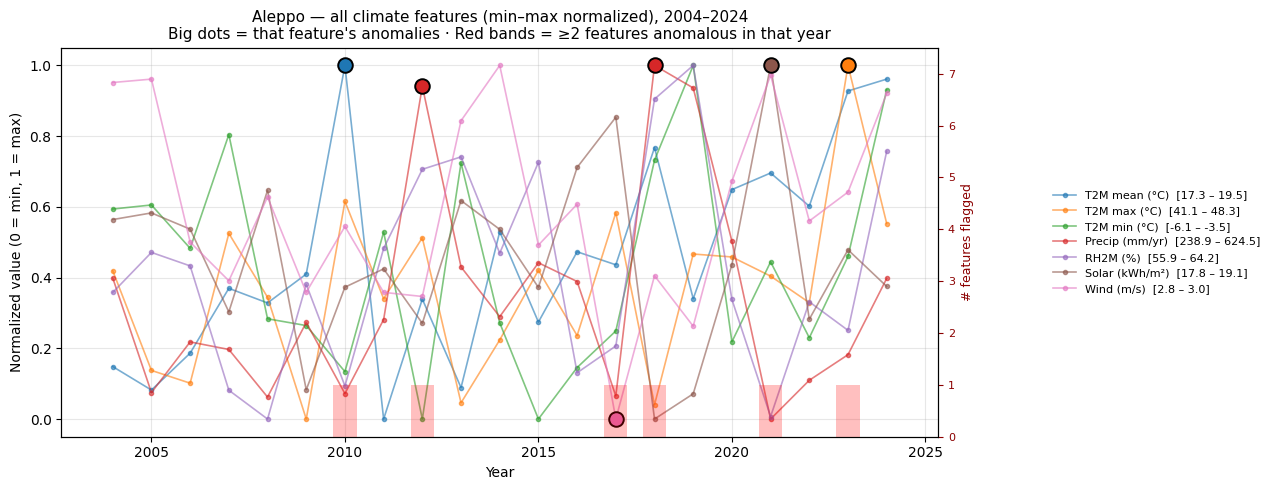

Aleppo         no strong anomaly years


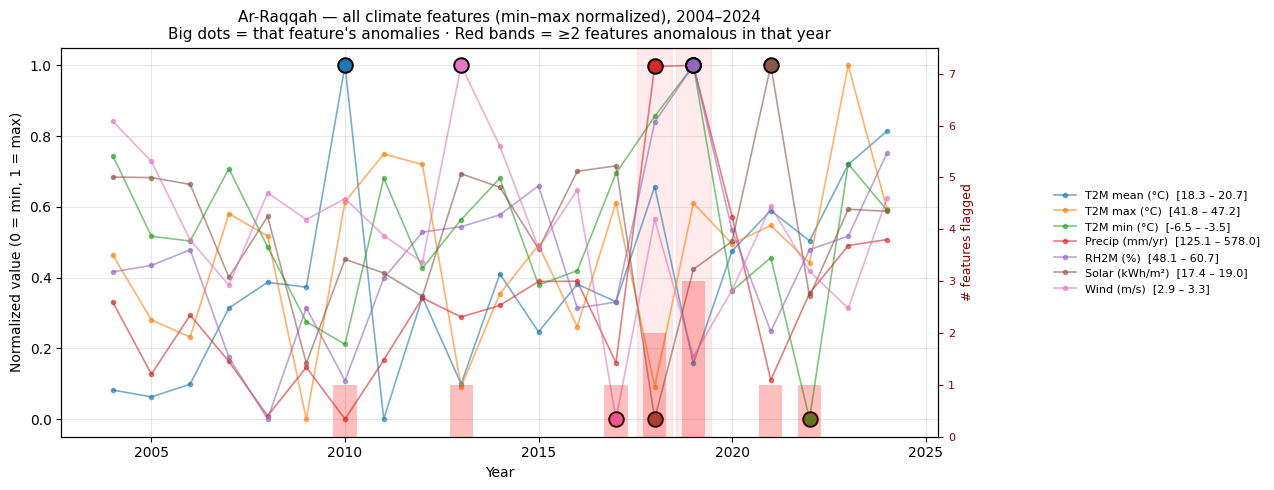

Ar-Raqqah      strong anomaly years: [2018, 2019]


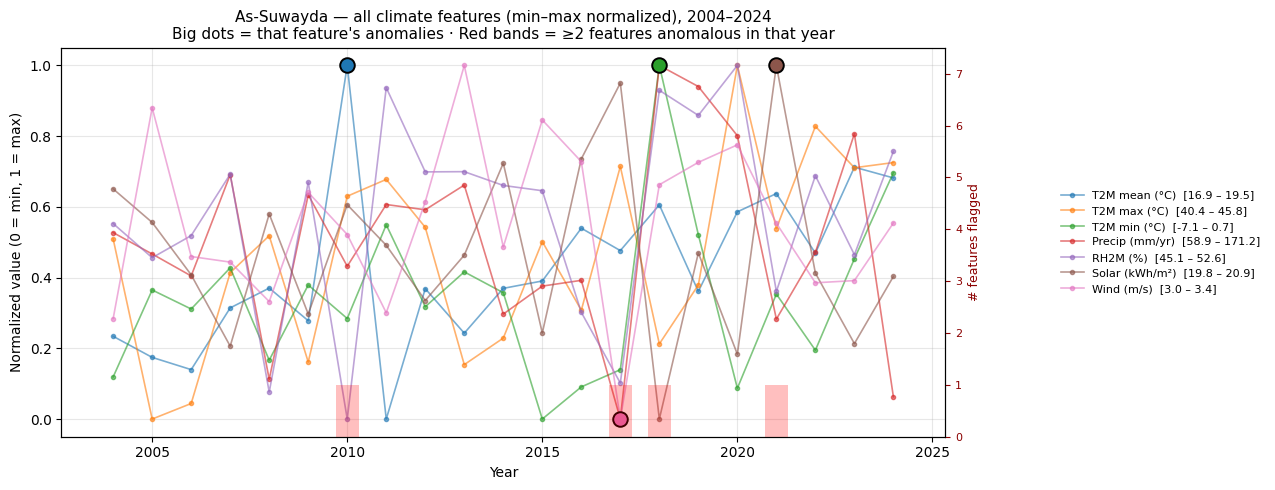

As-Suwayda     no strong anomaly years


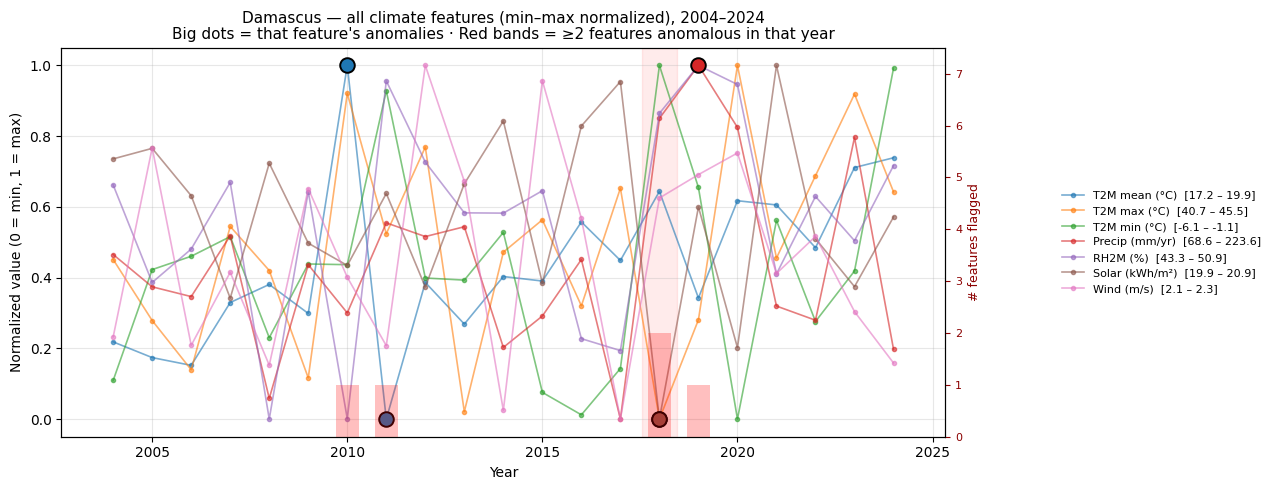

Damascus       strong anomaly years: [2018]


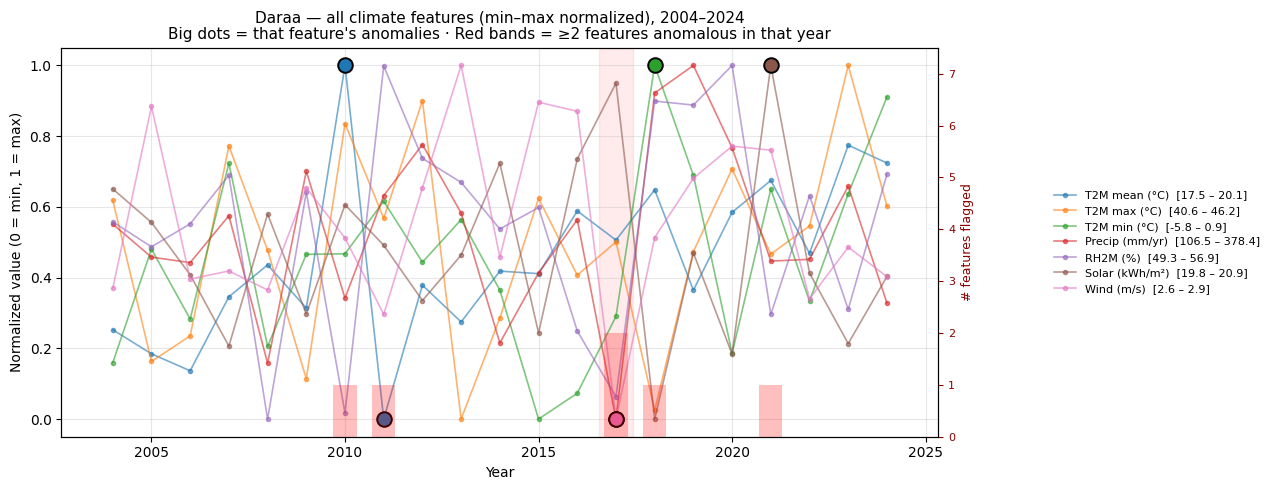

Daraa          strong anomaly years: [2017]


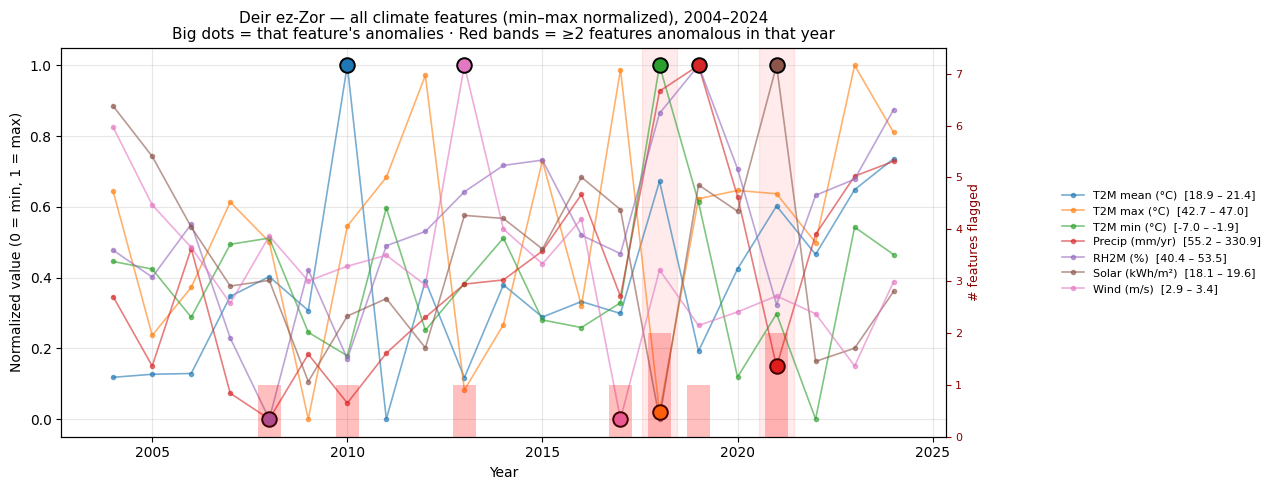

Deir ez-Zor    strong anomaly years: [2018, 2021]


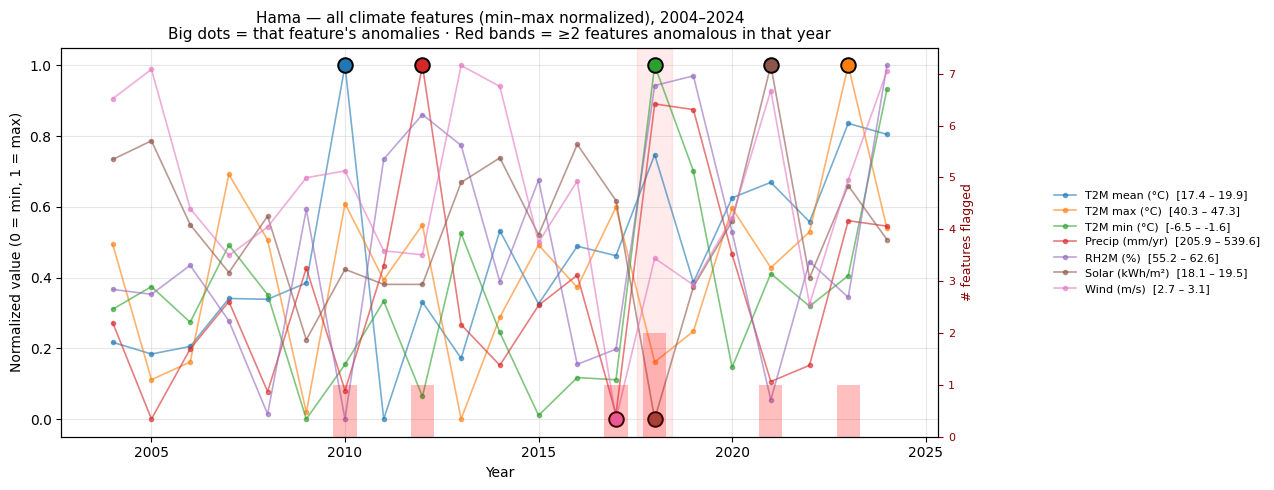

Hama           strong anomaly years: [2018]


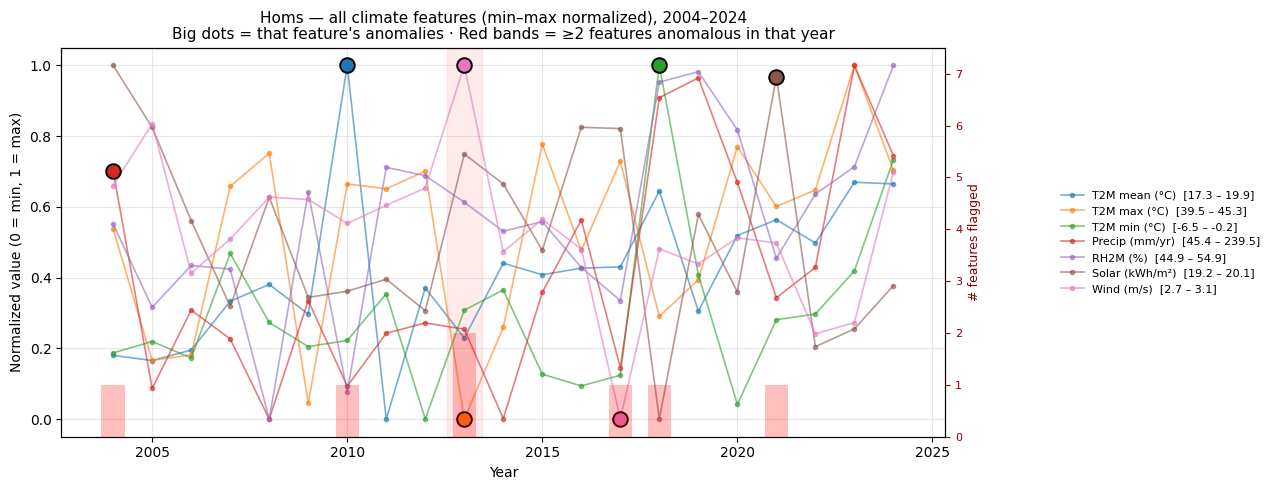

Homs           strong anomaly years: [2013]


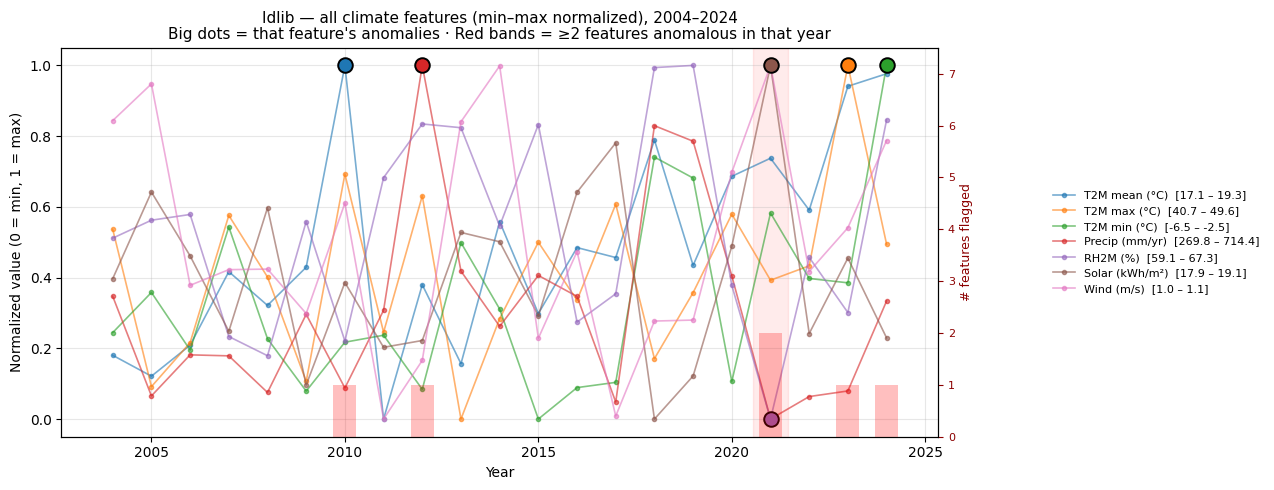

Idlib          strong anomaly years: [2021]


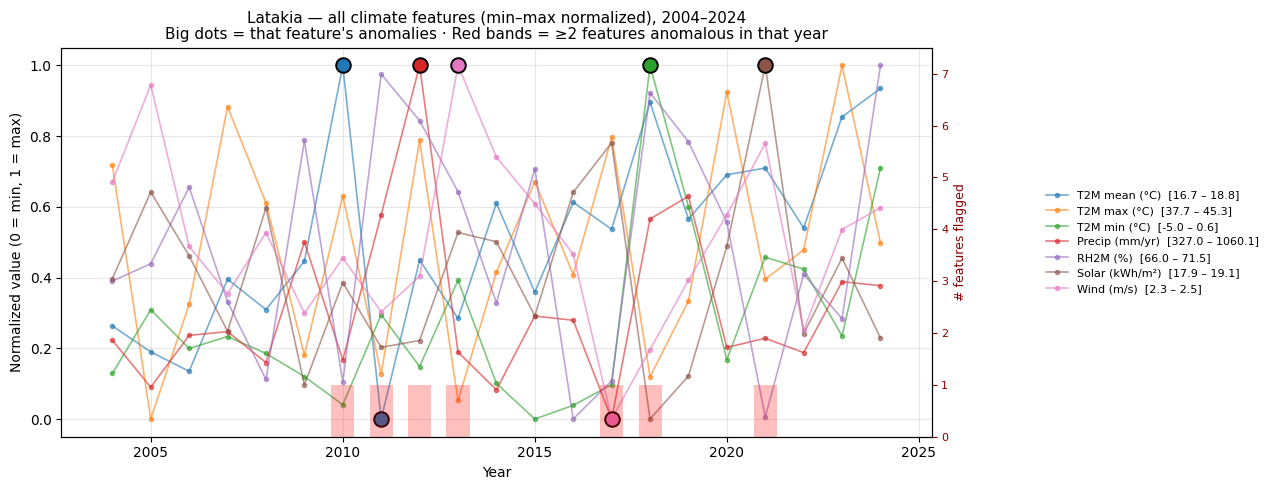

Latakia        no strong anomaly years


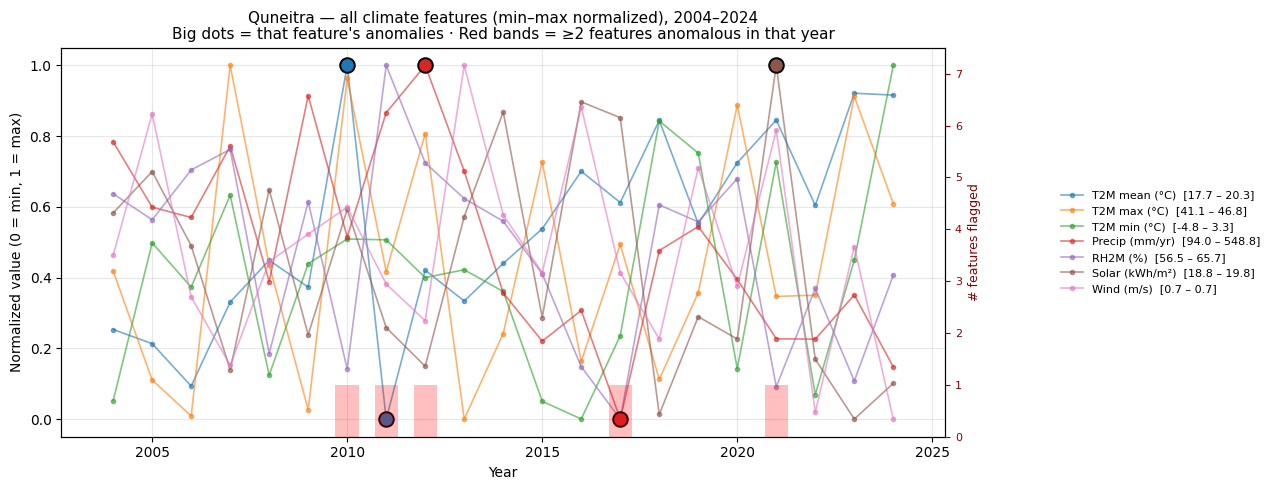

Quneitra       no strong anomaly years


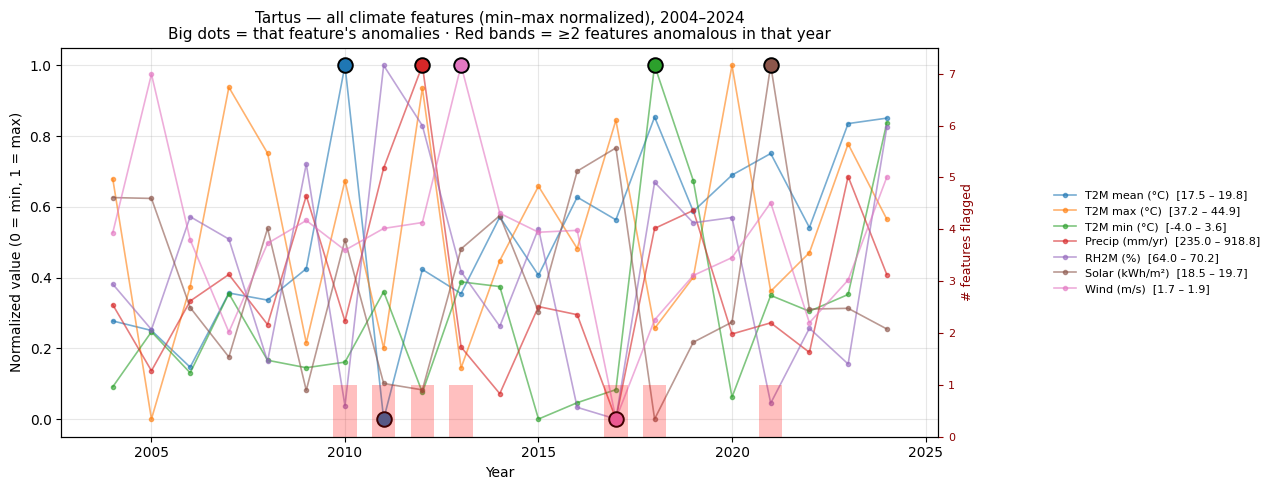

Tartus         no strong anomaly years


In [18]:
# ══════════════════════════════════════════════════════════════════
# Combined view — all climate features per governorate
# (same visual style as 00_anomaly_detection, filtered to chosen years)
# ══════════════════════════════════════════════════════════════════
for gov in govs:
    sub = (nasa_yearly_filtered[nasa_yearly_filtered['governorate'] == gov]
           .sort_values('year').reset_index(drop=True))
    if sub.empty:
        continue
    years = sub['year'].values

    # 1. Detect anomalies per feature for this governorate
    feat_masks = {}
    for feat in CLIMATE_FEATURES:
        _, _, _, m = detect_anomalies_for_gov(nasa_yearly_filtered, gov, feat)
        feat_masks[feat] = np.asarray(m, dtype=bool)

    anomaly_count = np.sum(list(feat_masks.values()), axis=0)

    # 2. Plot
    fig, ax = plt.subplots(figsize=(13, 5))
    for feat in CLIMATE_FEATURES:
        vals = sub[feat].values.astype(float)
        vmin, vmax = np.nanmin(vals), np.nanmax(vals)
        rng = vmax - vmin if (vmax - vmin) > 0 else 1.0
        norm = (vals - vmin) / rng

        line, = ax.plot(
            years, norm,
            marker='o', linewidth=1.2, markersize=3, alpha=0.6,
            label=f"{FEATURE_LABELS[feat]}  [{vmin:.1f} – {vmax:.1f}]",
        )
        color = line.get_color()

        mask = feat_masks[feat]
        if mask.any():
            ax.scatter(
                years[mask], norm[mask],
                s=110, color=color,
                edgecolors='black', linewidths=1.4,
                zorder=10, alpha=1.0,
            )

    # Shade years where ≥2 features are anomalous
    strong_years = years[anomaly_count >= 2]
    for y in strong_years:
        ax.axvspan(y - 0.45, y + 0.45, color='red', alpha=0.08, zorder=0)

    # Bottom strip: count of flagged features per year
    ax2 = ax.twinx()
    ax2.bar(years, anomaly_count, width=0.6, color='red', alpha=0.25, zorder=1)
    ax2.set_ylabel("# features flagged", color='darkred', fontsize=9)
    ax2.tick_params(axis='y', colors='darkred', labelsize=8)
    ax2.set_ylim(0, len(CLIMATE_FEATURES) + 0.5)

    ax.set_title(
        f"{gov} — all climate features (min–max normalized), "
        f"{CLIMATE_YEAR_START}–{CLIMATE_YEAR_END}\n"
        f"Big dots = that feature's anomalies · "
        f"Red bands = ≥2 features anomalous in that year",
        fontsize=11,
    )
    ax.set_xlabel("Year")
    ax.set_ylabel("Normalized value (0 = min, 1 = max)")
    ax.legend(loc='center left', bbox_to_anchor=(1.12, 0.5),
              fontsize=8, frameon=False)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    if len(strong_years):
        print(f"{gov:<14} strong anomaly years: {list(map(int, strong_years))}")
    else:
        print(f"{gov:<14} no strong anomaly years")

C:\Users\MK1349\AppData\Local\Temp\ipykernel_10224\2424406340.py:166: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


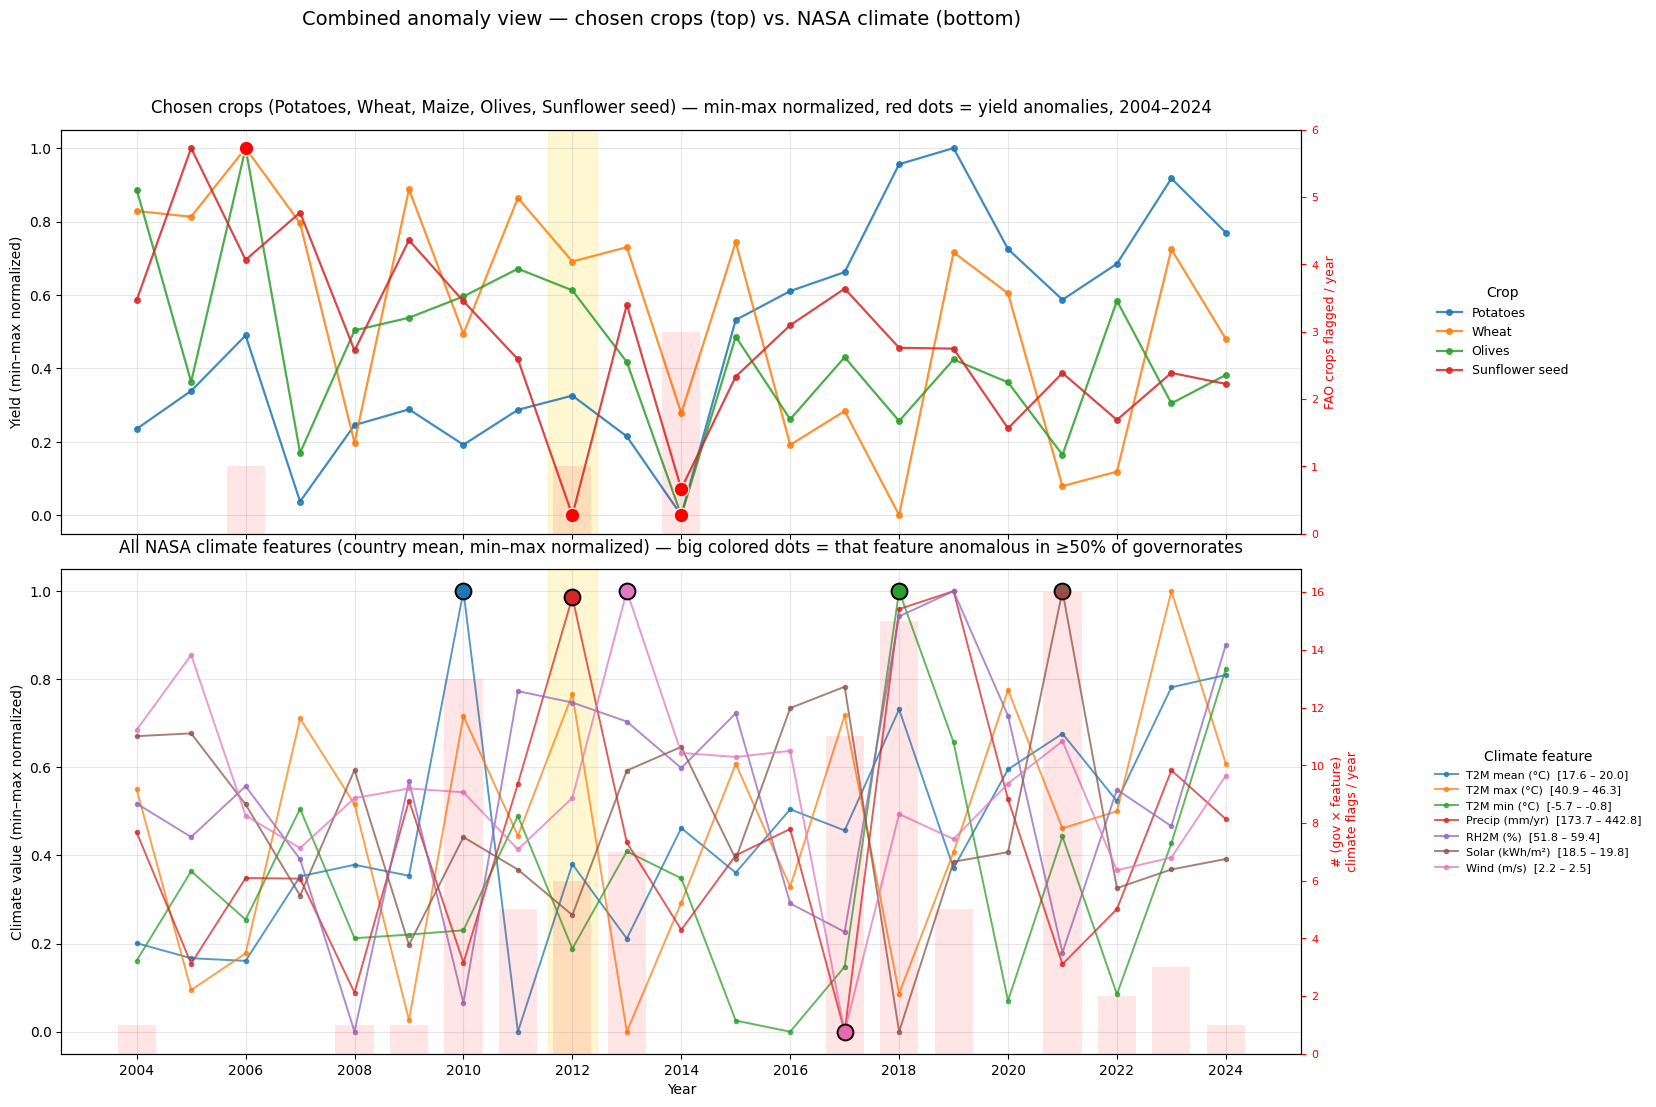


Years flagged in BOTH datasets (gold bands): [np.int64(2012)]

Anomaly years per climate feature (≥50% governorate consensus):
  T2M mean (°C)          [2010]
  T2M max (°C)           []
  T2M min (°C)           [2018]
  Precip (mm/yr)         [2012]
  RH2M (%)               []
  Solar (kWh/m²)         [2021]
  Wind (m/s)             [2013, 2017]


In [19]:
# ══════════════════════════════════════════════════════════════════
# Combined figure — chosen crops (top) vs. ALL NASA features (bottom)
#
# TOP:    5 FAO crops, min-max normalized, red dots = yield anomalies
# BOTTOM: 7 NASA climate features (country mean), min-max normalized,
#         big colored dots = that feature's anomaly years
# Gold bands: years flagged in BOTH datasets
# ══════════════════════════════════════════════════════════════════

# ── 1. FAO anomalies on the chosen crops ──────────────────────────
fao_years = sorted(fao_filtered['year'].dropna().astype(int).unique())
fao_anomaly_by_year = {y: 0 for y in fao_years}

for crop in CROPS:
    sub = (fao_filtered[fao_filtered['crop'] == crop]
           .sort_values('year').reset_index(drop=True))
    if len(sub) < 3:
        continue
    X = sub[['year', 'yield_hg_ha']].values.astype(float)
    resid = X[:, 1] - np.polyval(np.polyfit(X[:, 0], X[:, 1], 1), X[:, 0])
    resid_z = np.abs((resid - resid.mean()) / (resid.std() + 1e-12))
    mask = resid_z > 2.0
    for y, m in zip(sub['year'].astype(int), mask):
        if m:
            fao_anomaly_by_year[y] = fao_anomaly_by_year.get(y, 0) + 1

# ── 2. Per-year, per-feature NASA anomaly votes across governorates ─
# For each feature, for each year: how many of the 13 governorates
# flagged that feature as anomalous?
nasa_years = sorted(nasa_yearly_filtered['year'].unique())
n_govs = len(govs)

feature_votes = {feat: {y: 0 for y in nasa_years} for feat in CLIMATE_FEATURES}
for gov in govs:
    for feat in CLIMATE_FEATURES:
        _, _, _, m = detect_anomalies_for_gov(nasa_yearly_filtered, gov, feat)
        sub_years = (nasa_yearly_filtered[nasa_yearly_filtered['governorate'] == gov]
                     .sort_values('year')['year'].values)
        for y, flag in zip(sub_years, m):
            if flag:
                feature_votes[feat][y] = feature_votes[feat].get(y, 0) + 1

# A feature is "anomalous in year Y" if ≥ 50% of governorates flagged it
consensus_thresh = max(1, n_govs // 2)
feature_consensus = {
    feat: {y: (v >= consensus_thresh) for y, v in votes.items()}
    for feat, votes in feature_votes.items()
}

# Total climate flags per year (for gold-band agreement with FAO)
nasa_anomaly_by_year = {y: sum(feature_votes[f][y] for f in CLIMATE_FEATURES)
                        for y in nasa_years}

# ── 3. Draw the two-panel figure ──────────────────────────────────
fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(16, 12), sharex=True,
    gridspec_kw={'height_ratios': [1, 1.2], 'hspace': 0.08}
)

feat_colors = {f: plt.cm.tab10(i) for i, f in enumerate(CLIMATE_FEATURES)}

# ─── TOP: chosen FAO crops ───────────────────────────────────────
for crop in CROPS:
    sub = (fao_filtered[fao_filtered['crop'] == crop]
           .sort_values('year').reset_index(drop=True))
    if len(sub) < 3:
        continue
    vals = sub['yield_hg_ha'].values.astype(float)
    vmin, vmax = np.nanmin(vals), np.nanmax(vals)
    rng = vmax - vmin if (vmax - vmin) > 0 else 1.0
    norm = (vals - vmin) / rng
    ax_top.plot(sub['year'], norm, marker='o', linewidth=1.6,
                markersize=4, alpha=0.85, label=crop)

    X = sub[['year', 'yield_hg_ha']].values.astype(float)
    resid = X[:, 1] - np.polyval(np.polyfit(X[:, 0], X[:, 1], 1), X[:, 0])
    resid_z = np.abs((resid - resid.mean()) / (resid.std() + 1e-12))
    mask = resid_z > 2.0
    if mask.any():
        ax_top.scatter(sub['year'].values[mask], norm[mask],
                       color='red', s=110, zorder=5,
                       edgecolors='white', linewidths=0.9)

ax_top_far = ax_top.twinx()
ax_top_far.bar(fao_years, [fao_anomaly_by_year.get(y, 0) for y in fao_years],
               color='red', alpha=0.10, width=0.7)
ax_top_far.set_ylabel("FAO crops flagged / year", color='red', fontsize=9)
ax_top_far.tick_params(axis='y', colors='red', labelsize=8)
ax_top_far.set_ylim(0, len(CROPS) + 1)

ax_top.set_title(
    f"Chosen crops ({', '.join(CROPS)}) — min-max normalized, "
    f"red dots = yield anomalies, {CLIMATE_YEAR_START}–{CLIMATE_YEAR_END}",
    fontsize=12, pad=12,
)
ax_top.set_ylabel("Yield (min–max normalized)")
ax_top.legend(loc='center left', bbox_to_anchor=(1.10, 0.5),
              fontsize=9, frameon=False, title="Crop")
ax_top.grid(True, alpha=0.3)

# ─── BOTTOM: all NASA features, country mean, per-feature anomalies ─
for feat in CLIMATE_FEATURES:
    # Country-mean series for this feature
    mean_series = (nasa_yearly_filtered.groupby('year')[feat]
                   .mean().sort_index())
    years_f = mean_series.index.values.astype(int)
    vals    = mean_series.values.astype(float)

    vmin, vmax = np.nanmin(vals), np.nanmax(vals)
    rng_v = vmax - vmin if (vmax - vmin) > 0 else 1.0
    norm = (vals - vmin) / rng_v

    color = feat_colors[feat]
    ax_bot.plot(years_f, norm,
                marker='o', linewidth=1.4, markersize=3,
                alpha=0.75, color=color,
                label=f"{FEATURE_LABELS[feat]}  [{vmin:.1f} – {vmax:.1f}]")

    # Anomaly dots for this feature — where ≥50% of governorates flagged
    consensus_mask = np.array([feature_consensus[feat].get(int(y), False)
                               for y in years_f])
    if consensus_mask.any():
        ax_bot.scatter(
            years_f[consensus_mask], norm[consensus_mask],
            color=color, s=130, zorder=10,
            edgecolors='black', linewidths=1.4,
        )

# Bottom strip: total (gov × feature) flags per year
ax_bot_far = ax_bot.twinx()
values_nasa = [nasa_anomaly_by_year.get(y, 0) for y in nasa_years]
ax_bot_far.bar(nasa_years, values_nasa, width=0.7,
               color='red', alpha=0.10, zorder=0)
ax_bot_far.set_ylabel("# (gov × feature)\nclimate flags / year",
                      color='red', fontsize=9)
ax_bot_far.tick_params(axis='y', colors='red', labelsize=8)

ax_bot.set_title(
    "All NASA climate features (country mean, min–max normalized) — "
    "big colored dots = that feature anomalous in ≥50% of governorates",
    fontsize=12, pad=12,
)
ax_bot.set_ylabel("Climate value (min–max normalized)")
ax_bot.set_xlabel("Year")
ax_bot.legend(loc='center left', bbox_to_anchor=(1.10, 0.5),
              fontsize=8, frameon=False, title="Climate feature")
ax_bot.grid(True, alpha=0.3)

# ─── SHARED gold bands: years flagged in BOTH ────────────────────
common_anom_years = [
    y for y in fao_years
    if fao_anomaly_by_year.get(y, 0) > 0
    and nasa_anomaly_by_year.get(y, 0) >= 3
]
for y in common_anom_years:
    ax_top.axvspan(y - 0.45, y + 0.45, color='gold', alpha=0.18, zorder=0)
    ax_bot.axvspan(y - 0.45, y + 0.45, color='gold', alpha=0.18, zorder=0)

# Integer year ticks
ax_bot.set_xticks(range(CLIMATE_YEAR_START, CLIMATE_YEAR_END + 1, 2))

plt.suptitle(
    "Combined anomaly view — chosen crops (top) vs. NASA climate (bottom)",
    fontsize=14, y=0.98,
)
plt.tight_layout()
plt.show()

print(f"\nYears flagged in BOTH datasets (gold bands): {common_anom_years}")
print("\nAnomaly years per climate feature (≥50% governorate consensus):")
for feat in CLIMATE_FEATURES:
    flagged = sorted([int(y) for y, v in feature_consensus[feat].items() if v])
    print(f"  {FEATURE_LABELS[feat]:<22} {flagged}")

# Peak-yield year per crop

In [20]:
# ══════════════════════════════════════════════════════════════════
# Peak-yield year per crop → what did the climate look like that year?
# ══════════════════════════════════════════════════════════════════
import pandas as pd

print("=" * 110)
print("PEAK-YIELD YEAR PER CROP  →  NASA climate in that year")
print("=" * 110)

# Country-level NASA climate per year (mean across governorates)
nasa_country = (
    nasa_yearly_filtered
    .groupby('year')[CLIMATE_FEATURES]
    .mean()
    .reset_index()
)

# Long-format for pretty printing
nasa_country_long = nasa_country.melt(
    id_vars='year',
    value_vars=CLIMATE_FEATURES,
    var_name='feature',
    value_name='value',
)

for crop in CROPS:
    sub = (fao_filtered[fao_filtered['crop'] == crop]
           .sort_values('year').reset_index(drop=True))
    if sub.empty:
        print(f"\n[{crop}] — no data after filtering")
        continue

    # Peak-yield year
    peak_row   = sub.loc[sub['yield_hg_ha'].idxmax()]
    peak_year  = int(peak_row['year'])
    peak_yield = float(peak_row['yield_hg_ha'])

    # All years for this crop, ranked
    ranked = sub.sort_values('yield_hg_ha', ascending=False).reset_index(drop=True)

    # NASA climate in the peak year
    nasa_peak = nasa_country[nasa_country['year'] == peak_year]

    print(f"\n{'─' * 110}")
    print(f"  {crop}")
    print(f"{'─' * 110}")
    print(f"  Peak yield:    {peak_yield:>10,.1f} hg/ha")
    print(f"  Peak year:     {peak_year}")

    if nasa_peak.empty:
        print(f"  [WARN] No NASA climate data for {peak_year} "
              f"(outside {CLIMATE_YEAR_START}–{CLIMATE_YEAR_END}?)")
        continue

    # Per-feature: peak-year value, and how it compares to the crop's
    # whole-period mean & std for the same feature (a z-score).
    print(f"\n  Climate features in {peak_year} "
          f"(vs. {CLIMATE_YEAR_START}–{CLIMATE_YEAR_END} mean ± std):\n")
    print(f"    {'feature':<22} {'peak year':>12} {'period mean':>14} "
          f"{'Δ vs mean':>12} {'z-score':>10}")
    print(f"    {'-'*22} {'-'*12:>12} {'-'*14:>14} {'-'*12:>12} {'-'*10:>10}")

    period_means = nasa_country.set_index('year').loc[
        CLIMATE_YEAR_START:CLIMATE_YEAR_END
    ].mean()
    period_stds  = nasa_country.set_index('year').loc[
        CLIMATE_YEAR_START:CLIMATE_YEAR_END
    ].std()

    peak_dict = nasa_peak.iloc[0].to_dict()

    for feat in CLIMATE_FEATURES:
        v   = float(peak_dict[feat])
        mu  = float(period_means[feat])
        sd  = float(period_stds[feat])
        delta = v - mu
        z   = delta / sd if sd > 0 else 0.0

        # Mark z-scores that are >1σ away from mean
        marker = ""
        if abs(z) >= 1.5:
            marker = "  ←" if z > 0 else "  ←"
            if abs(z) >= 2.0:
                marker = "  ←!"   # strong outlier

        print(f"    {FEATURE_LABELS[feat]:<22} {v:>12,.2f} {mu:>14,.2f} "
              f"{delta:>+12,.2f} {z:>+10.2f}{marker}")

    # Top-3 yield years alongside their key climate features
    print(f"\n  Top 3 yield years for {crop}:")
    print(f"    {'year':<6} {'yield (hg/ha)':>16} "
          + " ".join(f"{f}" for f in CLIMATE_FEATURES))
    for _, row in ranked.head(3).iterrows():
        y = int(row['year'])
        y_val = float(row['yield_hg_ha'])
        climate_row = nasa_country[nasa_country['year'] == y]
        if climate_row.empty:
            print(f"    {y:<6} {y_val:>16,.1f}    (no NASA data)")
            continue
        cr = climate_row.iloc[0]
        feat_vals = " ".join(f"{cr[f]:>10,.2f}" for f in CLIMATE_FEATURES)
        print(f"    {y:<6} {y_val:>16,.1f} {feat_vals}")

print(f"\n{'=' * 110}")
print("Legend:")
print("  ! = |z| ≥ 2.0  (strong climate deviation)")
print("  ← = |z| ≥ 1.5  (notable deviation)")
print("  z = (peak-year value − period mean) / period std")
print(f"{'=' * 110}")

PEAK-YIELD YEAR PER CROP  →  NASA climate in that year

──────────────────────────────────────────────────────────────────────────────────────────────────────────────
  Potatoes
──────────────────────────────────────────────────────────────────────────────────────────────────────────────
  Peak yield:      25,630.5 hg/ha
  Peak year:     2019

  Climate features in 2019 (vs. 2004–2024 mean ± std):

    feature                   peak year    period mean    Δ vs mean    z-score
    ---------------------- ------------ -------------- ------------ ----------
    T2M mean (°C)                 18.47          18.66        -0.20      -0.32
    T2M max (°C)                  43.13          43.44        -0.32      -0.21
    T2M min (°C)                  -2.52          -4.08        +1.56      +1.24
    Precip (mm/yr)               442.82         290.78      +152.04      +2.01  ←!
    RH2M (%)                      59.43          55.90        +3.53      +1.67  ←
    Solar (kWh/m²)                19.0

# Per-crop climate fingerprint at peak-yield year

C:\Users\MK1349\AppData\Local\Temp\ipykernel_10224\3093409415.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.97])


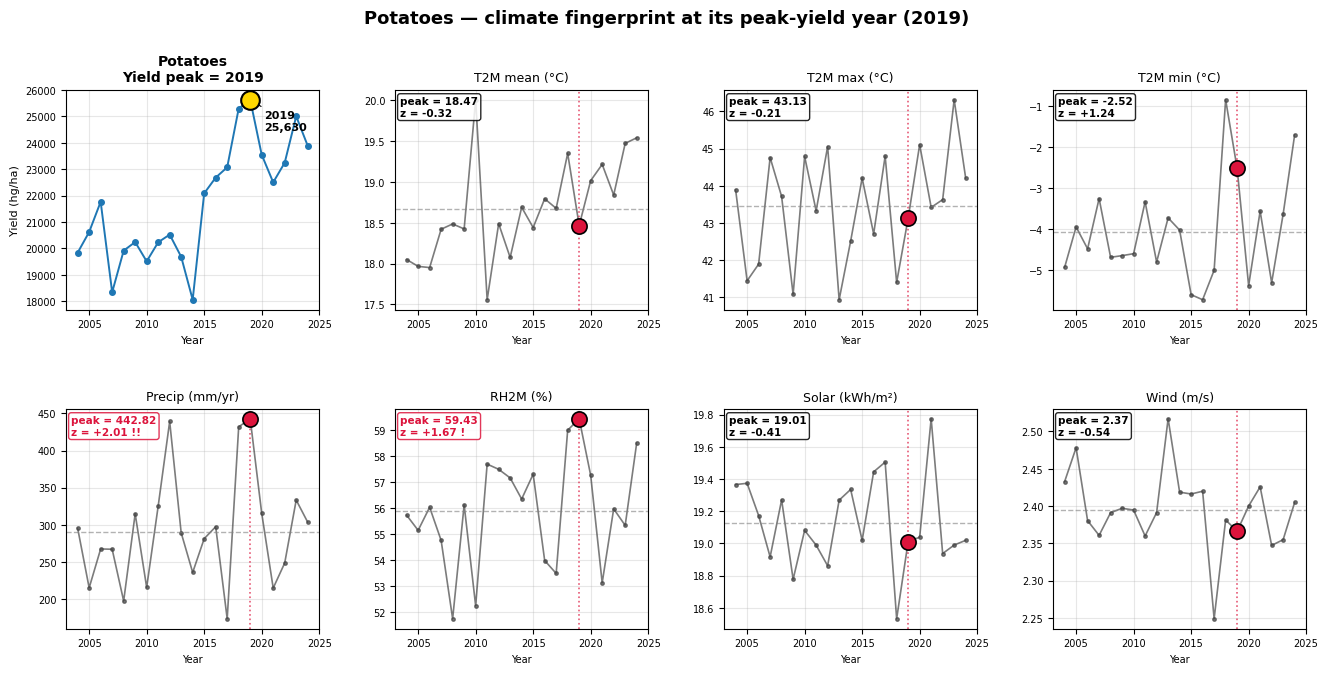

Potatoes       peak=2019  yield=    25,630  →  t2m z=-0.3  t2m_max z=-0.2  t2m_min z=+1.2  prectotcorr z=+2.0  rh2m z=+1.7  solar_kwh_m2 z=-0.4  ws2m z=-0.5


C:\Users\MK1349\AppData\Local\Temp\ipykernel_10224\3093409415.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.97])


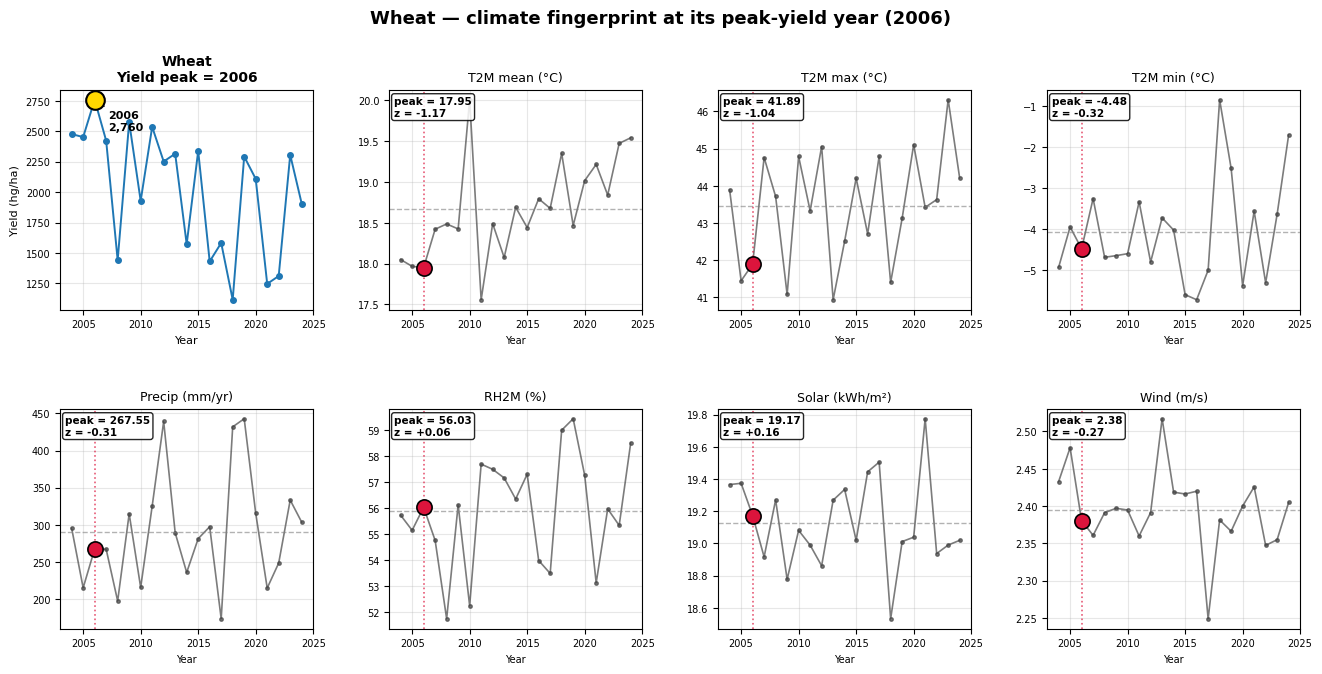

Wheat          peak=2006  yield=     2,760  →  t2m z=-1.2  t2m_max z=-1.0  t2m_min z=-0.3  prectotcorr z=-0.3  rh2m z=+0.1  solar_kwh_m2 z=+0.2  ws2m z=-0.3
[Maize] no data after filtering — skipping


C:\Users\MK1349\AppData\Local\Temp\ipykernel_10224\3093409415.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.97])


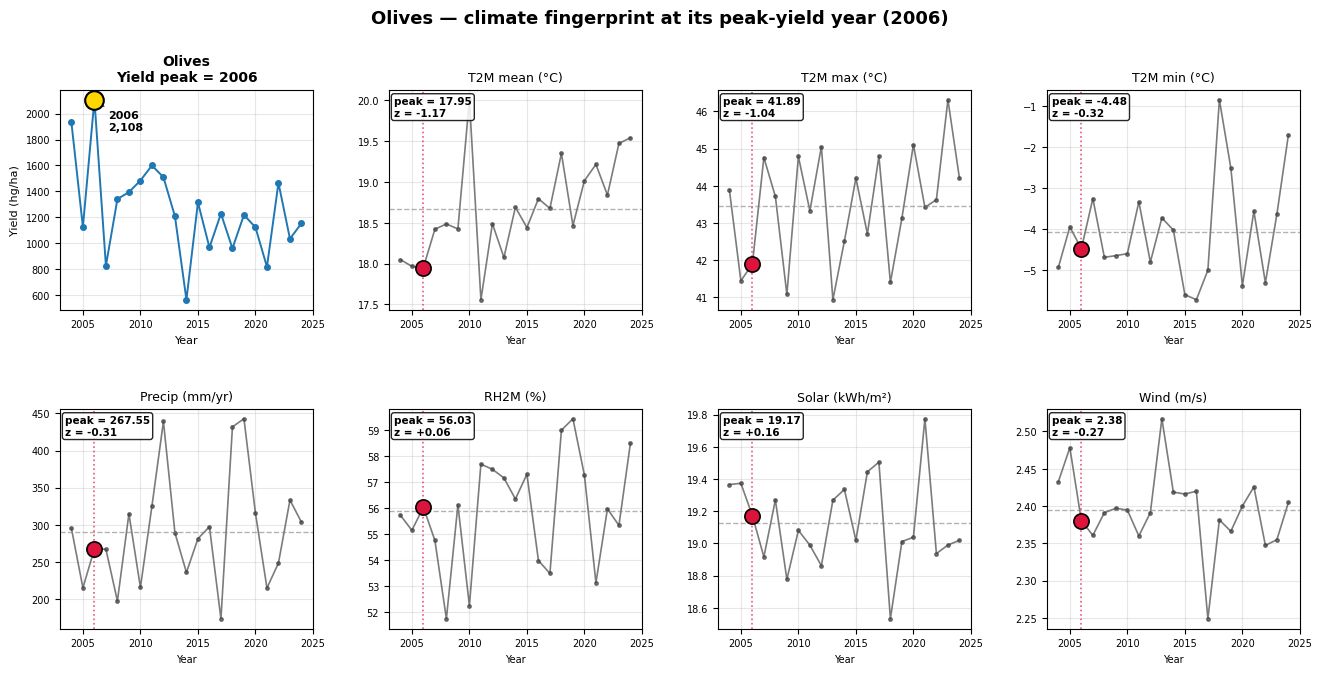

Olives         peak=2006  yield=     2,108  →  t2m z=-1.2  t2m_max z=-1.0  t2m_min z=-0.3  prectotcorr z=-0.3  rh2m z=+0.1  solar_kwh_m2 z=+0.2  ws2m z=-0.3


C:\Users\MK1349\AppData\Local\Temp\ipykernel_10224\3093409415.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.97])


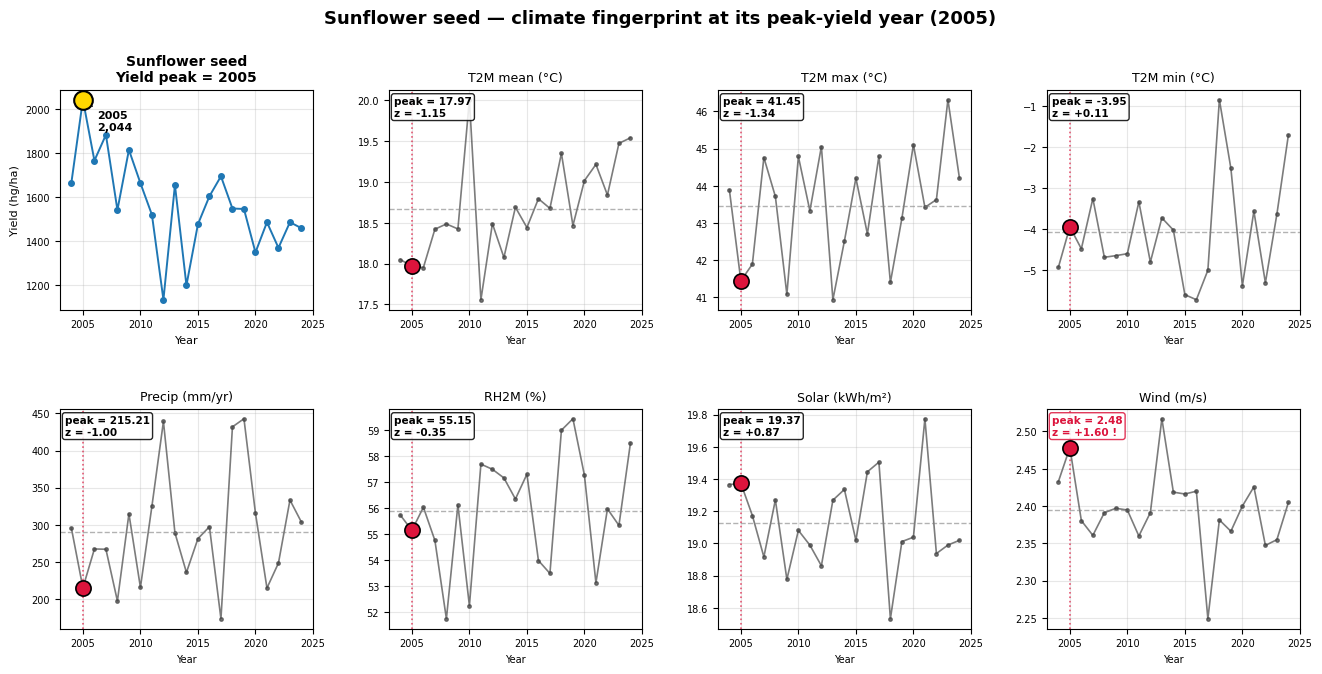

Sunflower seed peak=2005  yield=     2,044  →  t2m z=-1.1  t2m_max z=-1.3  t2m_min z=+0.1  prectotcorr z=-1.0  rh2m z=-0.4  solar_kwh_m2 z=+0.9  ws2m z=+1.6


In [21]:
# ══════════════════════════════════════════════════════════════════
# Per-crop climate fingerprint at peak-yield year
#
# For each crop, one figure with 7 small panels (2 rows × 4 cols),
# one panel per NASA climate feature. Each panel shows:
#   - The full-period time series (line)
#   - A vertical marker at the crop's peak-yield year
#   - A horizontal marker at the period mean
#   - A text annotation with the peak year's z-score for that feature
#
# This is the visual version of the Cell 4 table. Reading left-to-right
# in one crop's row tells you whether its peak year coincided with
# unusual rainfall, heat, solar, etc.
# ══════════════════════════════════════════════════════════════════

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

# Country-level NASA climate per year (already computed in Cell 4;
# recomputed here defensively so this cell works standalone)
if 'nasa_country' not in dir():
    nasa_country = (
        nasa_yearly_filtered
        .groupby('year')[CLIMATE_FEATURES]
        .mean()
        .reset_index()
    )

if 'period_means' not in dir():
    _period = nasa_country.set_index('year').loc[
        CLIMATE_YEAR_START:CLIMATE_YEAR_END
    ]
    period_means = _period.mean()
    period_stds  = _period.std()

for crop in CROPS:
    sub = (fao_filtered[fao_filtered['crop'] == crop]
           .sort_values('year').reset_index(drop=True))
    if sub.empty:
        print(f"[{crop}] no data after filtering — skipping")
        continue

    peak_row   = sub.loc[sub['yield_hg_ha'].idxmax()]
    peak_year  = int(peak_row['year'])
    peak_yield = float(peak_row['yield_hg_ha'])

    # 2 rows × 4 cols — 7 features + 1 spare panel for the yield summary
    fig = plt.figure(figsize=(16, 7))
    gs  = GridSpec(2, 4, figure=fig, hspace=0.45, wspace=0.30)

    # ── Top-left panel: this crop's yield curve with peak marked ──
    ax_y = fig.add_subplot(gs[0, 0])
    ax_y.plot(sub['year'], sub['yield_hg_ha'],
              marker='o', linewidth=1.4, markersize=4, color='#1f77b4')
    ax_y.scatter([peak_year], [peak_yield], s=180,
                 color='gold', edgecolors='black',
                 linewidths=1.5, zorder=5)
    ax_y.annotate(f"{peak_year}\n{peak_yield:,.0f}",
                  (peak_year, peak_yield),
                  textcoords='offset points', xytext=(10, -22),
                  fontsize=8, fontweight='bold',
                  arrowprops=dict(arrowstyle='-', color='black', lw=0.8))
    ax_y.set_title(f"{crop}\nYield peak = {peak_year}", fontsize=10,
                   fontweight='bold')
    ax_y.set_ylabel("Yield (hg/ha)", fontsize=8)
    ax_y.set_xlabel("Year", fontsize=8)
    ax_y.tick_params(labelsize=7)
    ax_y.grid(True, alpha=0.3)

    # ── Remaining 7 panels: one per climate feature ──
    for idx, feat in enumerate(CLIMATE_FEATURES):
        # Position: row 0 cols 1–3 → features 0,1,2
        #           row 1 cols 0–3 → features 3,4,5,6
        r = 0 if idx < 3 else 1
        c = (idx + 1) if r == 0 else (idx - 3)
        ax = fig.add_subplot(gs[r, c])

        years_f = nasa_country['year'].values
        vals    = nasa_country[feat].values

        # Full-period time series
        ax.plot(years_f, vals, marker='o', linewidth=1.2,
                markersize=2.5, color='#444444', alpha=0.7)

        # Period mean (dashed horizontal)
        mean_val = period_means[feat]
        ax.axhline(mean_val, color='gray', linestyle='--',
                   linewidth=1, alpha=0.6)

        # Peak-year vertical marker + point
        peak_val = (nasa_country.loc[nasa_country['year'] == peak_year, feat]
                    .values)
        if len(peak_val):
            pv = float(peak_val[0])
            ax.axvline(peak_year, color='crimson', linestyle=':',
                       linewidth=1.2, alpha=0.7)
            ax.scatter([peak_year], [pv], s=120,
                       color='crimson', edgecolors='black',
                       linewidths=1.2, zorder=5)

            # z-score annotation in the corner
            sd = period_stds[feat] if period_stds[feat] > 0 else 1.0
            z = (pv - mean_val) / sd
            tag = f"peak = {pv:.2f}\nz = {z:+.2f}"
            if abs(z) >= 2.0:
                tag += " !!"
            elif abs(z) >= 1.5:
                tag += " !"
            color = ('crimson' if abs(z) >= 1.5 else 'black')
            ax.text(0.02, 0.97, tag,
                    transform=ax.transAxes,
                    fontsize=7.5, verticalalignment='top',
                    color=color, fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.25',
                              facecolor='white',
                              edgecolor=color, alpha=0.85))
        else:
            ax.text(0.5, 0.5, f"no data\nfor {peak_year}",
                    transform=ax.transAxes, ha='center', va='center',
                    fontsize=8, color='red')

        ax.set_title(FEATURE_LABELS[feat], fontsize=9)
        ax.set_xlabel("Year", fontsize=7)
        ax.tick_params(labelsize=7)
        ax.grid(True, alpha=0.3)

    fig.suptitle(
        f"{crop} — climate fingerprint at its peak-yield year ({peak_year})",
        fontsize=13, fontweight='bold', y=0.995,
    )
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

    # Compact textual summary (useful if you screenshot the figure)
    print(f"{crop:<14} peak={peak_year}  "
          f"yield={peak_yield:>10,.0f}  →  "
          + "  ".join(
              f"{f} z={((nasa_country.loc[nasa_country['year']==peak_year, f].iloc[0] - period_means[f]) / (period_stds[f] if period_stds[f]>0 else 1)):+.1f}"
              for f in CLIMATE_FEATURES
              if not nasa_country.loc[nasa_country['year']==peak_year].empty
          )
    )

# Interactive 3D climate-space view

In [ ]:
# ══════════════════════════════════════════════════════════════════
# Interactive 3D climate-space view
#   - Background: all years as small gray points (context)
#   - Highlight:  one star per crop, at its peak-yield year
#   - Axes:       T2M (x), Solar (y), Precip (z)
#   - 4th dim:    Wind encoded as marker color (viridis)
#
# Requires:     pip install plotly
# Output:       interactive HTML saved to notebooks/figures/ AND
#               displayed inline in the notebook (rotatable)
# ══════════════════════════════════════════════════════════════════

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from pathlib import Path

# Country-level per-year climate (reuse if already computed)
if 'nasa_country' not in dir():
    nasa_country = (
        nasa_yearly_filtered
        .groupby('year')[CLIMATE_FEATURES]
        .mean()
        .reset_index()
    )

X_FEAT  = 't2m'
Y_FEAT  = 'solar_kwh_m2'
Z_FEAT  = 'prectotcorr'
W_FEAT  = 'ws2m'

# ── 1. Build the background cloud (all years, no crop distinction) ─
# We reuse the same country-level annual climate for context.
# Small, muted, unlabeled — its job is spatial reference, not data.
bg = nasa_country.copy()

# ── 2. Build the peak-year table (one row per crop) ────────────────
peaks = []
for crop in CROPS:
    sub = (fao_filtered[fao_filtered['crop'] == crop]
           .sort_values('year').reset_index(drop=True))
    if sub.empty:
        print(f"[{crop}] no data after filtering — skipping")
        continue

    peak_row   = sub.loc[sub['yield_hg_ha'].idxmax()]
    peak_year  = int(peak_row['year'])
    peak_yield = float(peak_row['yield_hg_ha'])

    # Look up climate for that year
    climate_row = nasa_country[nasa_country['year'] == peak_year]
    if climate_row.empty:
        print(f"[{crop}] peak year {peak_year} has no NASA climate row — skipping")
        continue

    cr = climate_row.iloc[0]
    peaks.append({
        'crop':       crop,
        'year':       peak_year,
        'yield':      peak_yield,
        't2m':        float(cr[X_FEAT]),
        'solar':      float(cr[Y_FEAT]),
        'precip':     float(cr[Z_FEAT]),
        'wind':       float(cr[W_FEAT]),
    })

peaks_df = pd.DataFrame(peaks)
if peaks_df.empty:
    raise SystemExit("No peak rows to plot — check CROPS / fao_filtered.")

print("Peak-year climate per crop:")
print(peaks_df[['crop', 'year', 'yield', 't2m', 'solar', 'precip', 'wind']]
      .to_string(index=False))

# ── 3. Build the interactive plotly figure ────────────────────────
fig = go.Figure()

# 3a. Background cloud — all years, small and gray
fig.add_trace(go.Scatter3d(
    x=bg[X_FEAT],
    y=bg[Y_FEAT],
    z=bg[Z_FEAT],
    mode='markers',
    marker=dict(
        size=3,
        color='rgba(180,180,180,0.35)',
        line=dict(width=0),
    ),
    name='All years (background)',
    hoverinfo='skip',
    showlegend=False,
))

# 3b. Peak stars — one per crop, colored by wind (viridis)
fig.add_trace(go.Scatter3d(
    x=peaks_df['t2m'],
    y=peaks_df['solar'],
    z=peaks_df['precip'],
    mode='markers+text',
    marker=dict(
        size=14,
        symbol='diamond',
        color=peaks_df['wind'],
        colorscale='Viridis',
        cmin=peaks_df['wind'].min() - 0.2,
        cmax=peaks_df['wind'].max() + 0.2,
        colorbar=dict(
            title='Wind<br>(m/s)',
            thickness=12,
            len=0.55,
            x=1.02,
        ),
        line=dict(color='black', width=2),
    ),
    text=peaks_df['crop'],
    textposition='top center',
    textfont=dict(size=11, color='black'),
    customdata=np.stack([
        peaks_df['crop'],
        peaks_df['year'],
        peaks_df['yield'],
        peaks_df['wind'],
    ], axis=-1),
    hovertemplate=(
        "<b>%{customdata[0]}</b><br>"
        "Peak year: %{customdata[1]}<br>"
        "Peak yield: %{customdata[2]:,.0f} hg/ha<br>"
        "T2M: %{x:.2f} °C<br>"
        "Solar: %{y:.2f} kWh/m²/day<br>"
        "Precip: %{z:.1f} mm/yr<br>"
        "Wind: %{customdata[3]:.2f} m/s"
        "<extra></extra>"
    ),
    name='Crop peak year',
))

# ── 4. Layout & camera ────────────────────────────────────────────
fig.update_layout(
    title=dict(
        text=("Peak-yield year per crop in climate space<br>"
              "<sub>T2M × Solar × Precip · color = wind speed · "
              "gray cloud = all years (context)</sub>"),
        x=0.5,
        xanchor='center',
    ),
    scene=dict(
        xaxis=dict(title='T2M mean (°C)',         backgroundcolor='white',
                   gridcolor='#e0e0e0'),
        yaxis=dict(title='Solar (kWh/m²/day)',    backgroundcolor='white',
                   gridcolor='#e0e0e0'),
        zaxis=dict(title='Precip (mm/yr)',        backgroundcolor='white',
                   gridcolor='#e0e0e0'),
        camera=dict(eye=dict(x=1.6, y=1.6, z=1.2)),   # initial angle
        aspectmode='cube',
    ),
    width=950,
    height=750,
    margin=dict(l=0, r=0, t=70, b=0),
    legend=dict(x=0.02, y=0.98, bgcolor='rgba(255,255,255,0.8)'),
)

# ── 5. Show inline (rotatable in Jupyter) ─────────────────────────
fig.show()

# ── 6. Save to disk for reviewer inspection ──────────────────────
FIG_DIR = Path('figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)
html_path = FIG_DIR / '3d_peak_climate_space.html'
fig.write_html(str(html_path), include_plotlyjs='cdn')
print(f"\n[saved] {html_path}")
print("        Open it in any browser to rotate / zoom.")

[Maize] no data after filtering — skipping
Peak-year climate per crop:
          crop  year    yield  t2m  solar  precip  wind
      Potatoes  2019 25,630.5 18.5   19.0   442.8   2.4
         Wheat  2006  2,759.9 18.0   19.2   267.6   2.4
        Olives  2006  2,107.6 18.0   19.2   267.6   2.4
Sunflower seed  2005  2,044.2 18.0   19.4   215.2   2.5



[saved] notebooks\figures\3d_peak_climate_space.html
        Open it in any browser to rotate / zoom.
